# OPW All-Time Episode Behavioural Intelligence Study

**Deliverable notebook** for deeper business and behavioural analysis of:

| Cohort | Definition |
|--------|------------|
| Orange | Leads with an Orange timestamp (any original birth source) |
| Purple | Leads with a Purple timestamp (any original birth source) |
| WhatsApp Born | Leads whose `bornSource` is WhatsApp |
| WhatsApp Reactivated | Leads with a WhatsApp secondarySource event marked as reactivation |
| WhatsApp Resubmitted | Leads with a WhatsApp secondarySource event that is **not** a reactivation |

**Analysis period:** all available history up to the current date (no date window filter).

**Methodological reference:** `leadstagehistories.ipynb` / `opw_episode_cohort_analysis.ipynb`, extended with:

- Actual ASBL lead age: `min(leads.createdAt, leadstagehistories createdAt)` via `masterLeadId` (else lead `_id`); Fresh = 1 project only
- Fresh-born vs cross-project-born classification
- Population averages that **include zero-activity leads**
- Within-lead episode change vs population-level episode change
- Lead-age × cohort behavioural analysis
- Evidence-based driver investigation (association, not causality)
- DOCX business report + Excel workbook

> Multi-label rule: if a lead qualifies for more than one cohort, **all matching flags are retained**. The lead is included in each matching cohort slice; it is not silently dropped or forcibly assigned to a single exclusive bucket.


## 1. Imports and setup

Load Athena credentials, visualisation libraries, and statistical tools.


In [1]:
import json
import os
import time
import warnings
from datetime import datetime
from pathlib import Path

import awswrangler as wr
import boto3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}" if pd.notna(x) else "")

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})

load_dotenv(Path.cwd() / ".env")


def _env(name, default=""):
    return (os.getenv(name) or default).strip()


AWS_REGION = _env("AWS_REGION", "ap-south-1")
ATHENA_DB = _env("ATHENA_DATABASE", "leadsdb-prod")
ATHENA_WORKGROUP = _env("ATHENA_WORKGROUP", "asbl_analytics_prod")
S3_OUTPUT = _env("ATHENA_OUTPUT_LOCATION", "s3://airflow-etl-db/athena_storage/")
AWS_ACCESS_KEY_ID = _env("AWS_ACCESS_KEY_ID")
AWS_SECRET_ACCESS_KEY = _env("AWS_SECRET_ACCESS_KEY")

# ponytail: this laptop has no ASBL profile; .env keys are the working auth path
session_kwargs = {"region_name": AWS_REGION}
if AWS_ACCESS_KEY_ID and AWS_SECRET_ACCESS_KEY:
    session_kwargs.update(
        aws_access_key_id=AWS_ACCESS_KEY_ID,
        aws_secret_access_key=AWS_SECRET_ACCESS_KEY,
    )
elif "ASBL" in boto3.Session().available_profiles:
    session_kwargs["profile_name"] = "ASBL"

session = boto3.Session(**session_kwargs)


def refresh_session():
    """Rebuild boto3 session so SigV4 clocks/credentials stay fresh on long Athena runs."""
    global session
    session = boto3.Session(**session_kwargs)
    return session


def athena_read(sql, retries=6):
    """Athena read with retry on expired signatures / throttling (common on long batch jobs)."""
    from botocore.exceptions import ClientError, BotoCoreError

    last_err = None
    for attempt in range(retries):
        try:
            return wr.athena.read_sql_query(
                sql=sql,
                database=ATHENA_DB,
                boto3_session=session,
                workgroup=ATHENA_WORKGROUP,
                s3_output=S3_OUTPUT,
                ctas_approach=False,
            )
        except (ClientError, BotoCoreError) as e:
            msg = str(e)
            code = ""
            if isinstance(e, ClientError):
                code = e.response.get("Error", {}).get("Code", "")
            retryable = code in {
                "InvalidSignatureException",
                "ExpiredToken",
                "ExpiredTokenException",
                "RequestExpired",
                "ThrottlingException",
                "TooManyRequestsException",
                "RequestTimeout",
            } or "Signature expired" in msg or "Request has expired" in msg
            if not retryable or attempt == retries - 1:
                raise
            last_err = e
            refresh_session()
            sleep_s = min(60, 2 ** attempt)
            print(f"Athena retry {attempt + 1}/{retries} after {code or type(e).__name__}; sleeping {sleep_s}s")
            time.sleep(sleep_s)
    raise last_err


def athena_batches(sql_template, ids, batch_size=None):
    batch_size = batch_size or globals().get("BATCH_SIZE", 1500)
    clean = list({
        str(x).replace(".0", "").strip()
        for x in ids
        if pd.notna(x) and str(x).strip() not in ("", "nan", "None")
    })
    parts = []
    n_batches = max(1, (len(clean) + batch_size - 1) // batch_size) if clean else 0
    t0 = time.time()
    for bi, i in enumerate(range(0, len(clean), batch_size)):
        if bi > 0 and bi % 20 == 0:
            refresh_session()
        batch = clean[i : i + batch_size]
        parts.append(athena_read(sql_template.format(ids=", ".join(f"'{b}'" for b in batch))))
        if bi % 5 == 0 or bi == n_batches - 1:
            print(f"  batch {bi + 1}/{n_batches} ({min(i + batch_size, len(clean)):,}/{len(clean):,} ids) [{time.time()-t0:.0f}s]")
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


def cache_path(name):
    return Path(globals().get("CACHE_DIR", Path("outputs/cache_alltime_bi"))) / f"{name}.parquet"


def load_or_fetch(name, fetch_fn):
    """Load parquet cache if present; otherwise fetch from Athena, save, return."""
    path = cache_path(name)
    force = bool(globals().get("FORCE_REFRESH", False))
    if path.exists() and not force:
        print(f"⚡ cache hit: {path.name}")
        return pd.read_parquet(path)
    print(f"⬇ fetching {name} from Athena…")
    t0 = time.time()
    df = fetch_fn()
    if df is None:
        df = pd.DataFrame()
    df.to_parquet(path, index=False)
    print(f"✓ cached {name}: {len(df):,} rows in {time.time()-t0:.0f}s → {path.name}")
    return df


print(f"Athena: db={ATHENA_DB} workgroup={ATHENA_WORKGROUP}")
print(f"Region: {AWS_REGION}")


Athena: db=leadsdb-prod workgroup=asbl_analytics_prod
Region: ap-south-1


## 2. Configuration

- **No date filter** on qualifying events — all history up to today.
- Episode history for every qualifying lead is retained in full (not active-episode only).
- Output artefacts land in `outputs/`.


In [ ]:
ANALYSIS_END = pd.Timestamp.now().normalize() + pd.Timedelta(hours=23, minutes=59, seconds=59)
WINDOW_START = pd.Timestamp("2000-01-01")  # all-time lower bound
WINDOW_START_STR = WINDOW_START.strftime("%Y-%m-%d %H:%M:%S")
ANALYSIS_END_STR = ANALYSIS_END.strftime("%Y-%m-%d %H:%M:%S")

EPISODE_ORDER = ["Episode 1", "Episode 2", "Episode 3", "Episode 4", "Episode 5+"]
COHORT_ORDER = [
    "Orange Born",
    "Purple Born",
    "WhatsApp Born",
    "WhatsApp Reactivated",
    "WhatsApp Resubmitted",
]
COHORT_FLAG = {
    "Orange Born": "is_orange_born",
    "Purple Born": "is_purple_born",
    "WhatsApp Born": "is_whatsapp_born",
    "WhatsApp Reactivated": "is_whatsapp_reactivated",
    "WhatsApp Resubmitted": "is_whatsapp_resubmitted",
}
MIN_SAMPLE_FLAG = 30

# --- Speed knobs (ponytail: cache once, skip the slowest optional Athena pulls) ---
BATCH_SIZE = 1500          # was 500 → fewer Athena round-trips
FORCE_REFRESH = False      # True = ignore parquet cache and re-pull from Athena
# Lead-age caches (new): leads_by_masterleadid.parquet, stage_first_by_lead_for_age.parquet
# Re-run from section 9 after pull; old asbl_history_by_gid is obsolete.
# Fresh = n_projects==1; born = min(leads.createdAt, stage-history createdAt).
LOAD_TRACK_EVENTS = False  # click-flag table is the slowest join; set True only if needed
LOAD_WEB_LOGS = True
LOAD_CALLS = True
LOAD_WHATSAPP = True

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
CACHE_DIR = OUTPUT_DIR / "cache_alltime_bi"
CACHE_DIR.mkdir(exist_ok=True)
OUTPUT_XLSX = OUTPUT_DIR / "OPW_AllTime_Episode_BI_Analysis.xlsx"
OUTPUT_DOCX = OUTPUT_DIR / "OPW_AllTime_Episode_BI_Report.docx"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

print(f"Analysis window: {WINDOW_START.date()} → {ANALYSIS_END.date()} (all-time)")
print(f"Cache: {CACHE_DIR} | FORCE_REFRESH={FORCE_REFRESH} | BATCH_SIZE={BATCH_SIZE}")
print(f"LOAD_TRACK_EVENTS={LOAD_TRACK_EVENTS} (biggest time sink when True)")
print(f"Excel → {OUTPUT_XLSX.resolve()}")
print(f"DOCX  → {OUTPUT_DOCX.resolve()}")


## 4. Lookup maps and analysis helpers

Shared utilities: ID→name maps, cohort event extraction, **population means (including zeros)**, safe % change, episode tables, and unit-aware formatting.


In [ ]:

_leadSourceDF = athena_read(f'SELECT _id, name FROM "{ATHENA_DB}"."leadsources"')
_projectDF = athena_read(f'SELECT _id, name FROM "{ATHENA_DB}"."projects"')

def id_name_map(lookup_df):
    return dict(zip(
        lookup_df["_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip(),
        lookup_df["name"].astype(str).str.strip(),
    ))

SOURCE_NAME_MAP = id_name_map(_leadSourceDF)
PROJECT_NAME_MAP = id_name_map(_projectDF)

def map_id_col(df, col, lookup):
    if col not in df.columns:
        return df
    ids = df[col].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    blank = df[col].isna() | ids.isin(["", "nan", "None", "<NA>", "NaT"])
    mapped = ids.map(lookup)
    df[col] = mapped.where(mapped.notna() & ~blank, ids.where(~blank, pd.NA))
    return df

def replace_ids_with_names(df):
    for col, mp in [("project", PROJECT_NAME_MAP), ("bornSource", SOURCE_NAME_MAP),
                    ("source", SOURCE_NAME_MAP), ("episode_source", SOURCE_NAME_MAP),
                    ("first_asbl_project", PROJECT_NAME_MAP)]:
        df = map_id_col(df, col, mp)
    return df

def _pick_col(df, *candidates):
    lower = {c.lower(): c for c in df.columns}
    for name in candidates:
        if name in df.columns: return name
        if name.lower() in lower: return lower[name.lower()]
    return None

def _parse_secondary_events(val):
    if not isinstance(val, str) or not val.strip() or val.strip() == "[]":
        return []
    try:
        parsed = json.loads(val)
    except Exception:
        return []
    return [x for x in parsed if isinstance(x, dict)] if isinstance(parsed, list) else []

def _classify_event_type(event_time, lead_created, episodes):
    if pd.isna(event_time):
        return "unknown"
    if pd.notna(lead_created) and abs((event_time - lead_created).total_seconds()) <= 86400:
        return "born"
    if episodes is not None and not episodes.empty:
        ep_starts = pd.to_datetime(episodes["episode_start_time"], errors="coerce")
        if ((ep_starts - event_time).abs() <= pd.Timedelta(days=1)).any():
            ep_match = episodes.loc[(ep_starts - event_time).abs() <= pd.Timedelta(days=1)]
            if (ep_match["episode_number"] > 1).any():
                return "reactivated"
    return "resubmitted"

def resolve_lead_flag_columns(leads_df):
    return {
        "is_orange": _pick_col(leads_df, "is_orange", "isorange", "isOrange"),
        "is_purple": _pick_col(leads_df, "is_purple", "ispurple", "ispurplelead", "isPurple"),
        "orange_time": _pick_col(leads_df, "orange_lead_time", "orangeleadtime", "orangeLeadTime"),
        "purple_time": _pick_col(leads_df, "purple_lead_time", "purpleleadtime", "purpleLeadTime"),
        "born_source": _pick_col(leads_df, "bornSource", "bornsource"),
        "secondary_source": _pick_col(leads_df, "secondarySource", "secondarysource"),
        "lead_created": _pick_col(leads_df, "lead_createdAt", "createdat", "createdAt"),
        "lead_id": _pick_col(leads_df, "lead", "_id"),
    }

def build_whatsapp_source_ids(source_df):
    name_col = _pick_col(source_df, "name")
    id_col = _pick_col(source_df, "_id")
    if not name_col or not id_col:
        return set()
    mask = source_df[name_col].astype(str).str.contains("whatsapp", case=False, na=False)
    return set(source_df.loc[mask, id_col].astype(str).str.strip())

def extract_lead_qualifying_events(lead_row, cols, wa_source_ids, source_name_map, window_start, window_end, episodes=None):
    events = []
    lead_created = pd.to_datetime(lead_row.get(cols["lead_created"]), errors="coerce") if cols["lead_created"] else pd.NaT
    def add_event(channel, event_time, event_type=None):
        if pd.isna(event_time) or event_time < window_start or event_time > window_end:
            return
        events.append({"channel": channel, "event_time": event_time,
                       "event_type": event_type or _classify_event_type(event_time, lead_created, episodes)})
    if cols["orange_time"]:
        orange_ts = pd.to_datetime(lead_row.get(cols["orange_time"]), errors="coerce")
        if pd.notna(orange_ts):
            add_event("Orange", orange_ts)
    if cols["purple_time"]:
        purple_ts = pd.to_datetime(lead_row.get(cols["purple_time"]), errors="coerce")
        if pd.notna(purple_ts):
            add_event("Purple", purple_ts)
    born_source = str(lead_row.get(cols["born_source"], "")).strip() if cols["born_source"] else ""
    born_source_name = source_name_map.get(born_source, born_source).lower()
    if born_source in wa_source_ids or "whatsapp" in born_source_name:
        add_event("WhatsApp", lead_created, "born")
    for item in _parse_secondary_events(lead_row.get(cols["secondary_source"]) if cols["secondary_source"] else None):
        event_time = pd.to_datetime(item.get("date"), errors="coerce")
        if pd.isna(event_time) or event_time < window_start or event_time > window_end:
            continue
        src = str(item.get("source", "")).strip()
        src_name = source_name_map.get(src, src).lower()
        is_react = item.get("isReactivation")
        is_reactivation = is_react is True or str(is_react).lower() == "true"
        event_type = "reactivated" if is_reactivation else "resubmitted"
        if src in wa_source_ids or "whatsapp" in src_name:
            add_event("WhatsApp", event_time, event_type)
    return events

META_EXCLUDE = {
    "lead", "lead_clean", "leadId", "lead_oid", "masterLeadId", "globalId", "visitorId",
    "project", "status", "episode_id", "episode_number", "episode_group",
    "episode_start_time", "episode_end_time", "lead_createdAt", "start_stage", "end_stage",
    "stage_before_ni", "stage_transition_path", "cancellation_reason_at_episode_end",
    "bornSource", "source", "secondarySource", "episode_source",
    "original_source", "qualifying_source", "reactivation_source", "resubmission_source",
    "qualifying_event_types", "qualifying_channels", "cohort_labels",
    "first_qualifying_event_time", "last_qualifying_event_time",
    "qualifying_event_count", "prev_episode_number", "lead_curr", "lead_prev", "transition_pair",
    "first_asbl_project", "first_asbl_birth_ts", "first_asbl_lead", "fresh_cross_status", "lead_age_bucket",
    "identity_key", "identity_type", "master_clean", "n_projects", "linked_lead_count",
    "current_project_birth_ts", "current_project_id",
    "lead_age_in_project_at_episode_days",
    "lead_age_current_project_days",
    "lead_age_asbl_days",
    "is_orange_born", "is_purple_born", "is_whatsapp_born", "is_whatsapp_reactivated", "is_whatsapp_resubmitted",
    "is_orange_lead", "is_purple_lead", "is_whatsapp_lead", "is_fresh_born", "is_cross_project",
}

print(f"Lead sources: {len(_leadSourceDF):,} | Projects: {len(_projectDF):,}")
print(f"WhatsApp source IDs: {len(build_whatsapp_source_ids(_leadSourceDF)):,}")



In [ ]:
METRIC_DICT = [
    {"feature": "total_web_timespent", "description": "Total website time spent in episode", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "total_session_count", "description": "Web session count", "unit": "Sessions", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "active_session_count", "description": "Sessions with time spent > 0", "unit": "Sessions", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "avg_web_activity", "description": "Web seconds per active session", "unit": "Seconds / session", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "home_timespent", "description": "Home page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "price_timespent", "description": "Price page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "plan_timespent", "description": "Plan page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "location_timespent", "description": "Location page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "amenities_timespent", "description": "Amenities page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "media_timespent", "description": "Media page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "specifications_timespent", "description": "Specifications page time", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "is_site_visit_book_clicked", "description": "Clicked book site visit", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "is_whatsapp_clicked", "description": "Clicked WhatsApp on web", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "is_brochure_downloaded", "description": "Brochure download click", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "is_price_sheet_viewed", "description": "Price sheet view", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "is_cost_sheet_clicked", "description": "Cost sheet click", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "total_call_duration", "description": "Answered call duration", "unit": "Seconds", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "time"},
    {"feature": "total_answered_calls", "description": "Answered calls", "unit": "Calls", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "total_inbound_calls", "description": "Inbound calls", "unit": "Calls", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "total_outbound_calls", "description": "Outbound calls", "unit": "Calls", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "total_attempted_calls", "description": "Attempted calls", "unit": "Calls", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "total_agent_missed_calls", "description": "Agent-missed calls", "unit": "Calls", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "total_customer_missed_calls", "description": "Customer-missed calls", "unit": "Calls", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "pickup_ratio", "description": "Answered / attempted", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "episode_whatsapp_inbound_count", "description": "Inbound WhatsApp messages", "unit": "Interactions", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "has_whatsapp_inbound_in_episode", "description": "Any inbound WhatsApp", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "days_to_first_whatsapp_inbound", "description": "Days to first WA inbound (−1 = none)", "unit": "Days", "aggregation": "Mean among WA-active", "kind": "days_sentinel"},
    {"feature": "days_to_last_whatsapp_inbound", "description": "Days to last WA inbound (−1 = none)", "unit": "Days", "aggregation": "Mean among WA-active", "kind": "days_sentinel"},
    {"feature": "episode_duration_days", "description": "Episode length", "unit": "Days", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
    {"feature": "episode_stage_movement_count", "description": "Stage movements", "unit": "Movements", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "resubmission_count_in_episode", "description": "Resubmissions in episode", "unit": "Events", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "count"},
    {"feature": "is_resubmitted_in_episode", "description": "Any resubmission", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "did_reach_site_visit_in_episode", "description": "Reached site visit", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "is_reactivated_episode", "description": "Has a later episode", "unit": "Rate (0-1) → display %", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "rate"},
    {"feature": "lead_age_at_episode_start_days", "description": "ASBL age at episode start (episode_start − first born)", "unit": "Days", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
    {"feature": "lead_age_at_project_birth_days", "description": "ASBL age when current project record was born (project born − first born)", "unit": "Days", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
    {"feature": "lead_age_asbl_days", "description": "Actual ASBL system age (analysis end − first born)", "unit": "Days", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
    {"feature": "lead_age_current_project_days", "description": "Age of current project record (analysis end − project born)", "unit": "Days", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
    {"feature": "lead_age_in_project_at_episode_days", "description": "Time since project birth at episode start", "unit": "Days", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
    {"feature": "lead_age_months", "description": "ASBL age in months", "unit": "Months", "aggregation": "Mean (zeros + IQR outliers dropped)", "kind": "days"},
]
df_metric_dict = pd.DataFrame(METRIC_DICT)
METRIC_META = {r["feature"]: r for r in METRIC_DICT}
print(f"Metric dictionary: {len(METRIC_DICT)} features")


def feature_columns(df):
    cols = []
    for c in df.columns:
        if c in META_EXCLUDE or c.endswith(("_curr", "_prev")):
            continue
        if c.startswith("is_") and c not in METRIC_META and c not in {
            "is_site_visit_book_clicked","is_whatsapp_clicked","is_brochure_downloaded",
            "is_price_sheet_viewed","is_cost_sheet_clicked","is_resubmitted_in_episode",
            "is_reactivated_episode",
        }:
            # keep binary behavioural flags that are in METRIC_META only
            if c not in METRIC_META:
                continue
        if pd.api.types.is_numeric_dtype(df[c]):
            cols.append(c)
    # prefer metric dict order, then extras
    ordered = [f for f in df_metric_dict["feature"] if f in cols]
    extras = [c for c in cols if c not in ordered]
    return ordered + extras

def pct_change_safe(prev, curr):
    """Return (abs_change, pct_label, kind). Never emit inf."""
    if pd.isna(prev) or pd.isna(curr):
        return np.nan, "Insufficient data", "na"
    abs_chg = curr - prev
    if prev == 0 and curr == 0:
        return 0.0, "No Activity", "zero"
    if prev == 0 and curr != 0:
        return abs_chg, "New Activity", "new"
    return abs_chg, f"{(abs_chg / prev) * 100:.2f}%", "pct"

def format_value(feature, value):
    meta = METRIC_META.get(feature, {"unit": "", "kind": "count"})
    if pd.isna(value):
        return "n/a"
    kind = meta.get("kind", "count")
    unit = meta.get("unit", "")
    if kind == "rate":
        return f"{value * 100:.2f}%"
    if kind in ("time",):
        return f"{value:.2f} seconds"
    if kind in ("days", "days_sentinel"):
        return f"{value:.2f} days"
    if "Months" in unit:
        return f"{value:.2f} months"
    if "Calls" in unit:
        return f"{value:.2f} calls"
    if "Interactions" in unit:
        return f"{value:.2f} interactions"
    if "Sessions" in unit:
        return f"{value:.2f} sessions"
    if "Movements" in unit or "Rows" in unit or "Events" in unit:
        return f"{value:.2f}"
    return f"{value:.2f} {unit}".strip()

def axis_label(feature):
    meta = METRIC_META.get(feature, {"description": feature, "unit": ""})
    unit = meta.get("unit", "")
    if "display %" in unit or meta.get("kind") == "rate":
        return f"{meta.get('description', feature)} (%)"
    short_unit = unit.split("→")[0].strip()
    return f"{meta.get('description', feature)} ({short_unit})"

def is_binary_or_rate(s, feature=None):
    kind = METRIC_META.get(feature or "", {}).get("kind")
    if kind == "rate":
        return True
    s = pd.to_numeric(s, errors="coerce").dropna()
    if s.empty:
        return False
    return set(s.unique()).issubset({0, 1, 0.0, 1.0})


def without_outliers(s, drop_zeros=True):
    """Drop zeros (optional) then Tukey 1.5×IQR outliers."""
    s = pd.to_numeric(s, errors="coerce").dropna()
    if drop_zeros:
        s = s[s > 0]
    if len(s) < 4:
        return s
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        return s
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s[(s >= lo) & (s <= hi)]


def _r2(x):
    return round(float(x), 2) if pd.notna(x) else np.nan


def population_mean(s, feature=None):
    """PRIMARY avg: exclude zeros + IQR outliers. Rates keep full 0/1 mean (rate). All values to 2 d.p."""
    kind = METRIC_META.get(feature or "", {}).get("kind")
    s = pd.to_numeric(s, errors="coerce")
    if kind == "days_sentinel":
        s = s.replace(-1, np.nan).dropna()
        s = without_outliers(s, drop_zeros=True)
        return _r2(s.mean()) if len(s) else np.nan
    if is_binary_or_rate(s, feature):
        s = s.dropna()
        return _r2(s.mean()) if len(s) else np.nan
    s = without_outliers(s.dropna(), drop_zeros=True)
    return _r2(s.mean()) if len(s) else np.nan


def active_mean(s, feature=None):
    """Same as population_mean (zeros + outliers already dropped). Kept for secondary views."""
    return population_mean(s, feature)


def round_df(df):
    """Round all numeric columns to 2 decimal places for display/export."""
    if df is None or getattr(df, "empty", True):
        return df
    out = df.copy()
    num_cols = out.select_dtypes(include=[np.number]).columns
    out[num_cols] = out[num_cols].round(2)
    return out

def episode_average_table(df, features=None, how="population"):
    features = list(features or feature_columns(df))
    out = pd.DataFrame({"Feature": features})
    fn = population_mean if how == "population" else active_mean
    for ep in EPISODE_ORDER:
        sub = df.loc[df["episode_group"] == ep]
        out[ep] = [fn(sub[f], f) if f in sub.columns else np.nan for f in features]
        out[f"n_{ep}"] = [len(sub)] * len(features) if features else []
    # simplify: one n row separately; drop per-feature n cols if duplicated
    n_cols = [c for c in out.columns if c.startswith("n_")]
    if n_cols:
        # keep sample sizes only once via separate table; drop duplicated n_* from feature table
        out = out.drop(columns=n_cols)
    out["Unit"] = [METRIC_META.get(f, {}).get("unit", "") for f in features]
    return round_df(out)

def episode_sample_size_table(df):
    return pd.DataFrame([
        {"Episode": ep, "Unique Leads": int(df.loc[df["episode_group"] == ep, "lead"].nunique()),
         "Total Episodes": int(len(df[df["episode_group"] == ep]))}
        for ep in EPISODE_ORDER
    ])

def episode_change_table(episode_avgs):
    rows = []
    transitions = list(zip(EPISODE_ORDER, EPISODE_ORDER[1:]))
    for _, row in episode_avgs.iterrows():
        feat = row["Feature"]
        kind = METRIC_META.get(feat, {}).get("kind", "count")
        rec = {"Feature": feat, "Unit": row.get("Unit", METRIC_META.get(feat, {}).get("unit", ""))}
        vals = []
        for ep in EPISODE_ORDER:
            rec[f"{ep}"] = row[ep]
            vals.append(row[ep])
        for prev_ep, curr_ep in transitions:
            prev, curr = row[prev_ep], row[curr_ep]
            abs_chg, pct_lab, _ = pct_change_safe(prev, curr)
            rec[f"Abs Δ {prev_ep}→{curr_ep}"] = abs_chg
            if kind == "rate" and pd.notna(abs_chg):
                rec[f"pp Δ {prev_ep}→{curr_ep}"] = abs_chg * 100  # percentage points
            rec[f"% Δ {prev_ep}→{curr_ep}"] = pct_lab
        # trend
        clean = [v for v in vals if pd.notna(v)]
        if len(clean) < 2:
            rec["Overall Trend"] = "Insufficient data"
        else:
            deltas = [b - a for a, b in zip(clean, clean[1:])]
            if all(d > 0 for d in deltas):
                rec["Overall Trend"] = "Increasing"
            elif all(d < 0 for d in deltas):
                rec["Overall Trend"] = "Decreasing"
            else:
                rec["Overall Trend"] = "Mixed"
        rows.append(rec)
    return pd.DataFrame(rows)

def assign_lead_age_bucket(days):
    if pd.isna(days):
        return "Unknown"
    d = float(days)
    if d <= 0:
        return "Fresh / 0 days"
    if d <= 7:
        return "1–7 days"
    if d <= 30:
        return "8–30 days"
    if d <= 90:
        return "31–90 days"
    if d <= 180:
        return "91–180 days"
    if d <= 365:
        return "181–365 days"
    return "365+ days"

AGE_BUCKET_ORDER = ["Fresh / 0 days", "1–7 days", "8–30 days", "31–90 days", "91–180 days", "181–365 days", "365+ days", "Unknown"]

def save_fig(name):
    path = FIG_DIR / name
    plt.tight_layout()
    plt.savefig(path, dpi=140, bbox_inches="tight")
    print(f"Saved {path}")
    plt.show()

print("Analysis helpers loaded (mean excludes zeros + IQR outliers; rates keep 0/1; 2 d.p.).")



## 5. Data loading — all-time OPW candidates

**Why it was slow:** all-time ≈ 100k+ leads × many Athena round-trips.

**What we changed:** parquet cache under `outputs/cache_alltime_bi/`, batch size 1500, no 40× LIKE scan.
First run still hits Athena; **re-runs should be minutes/seconds**.


In [5]:
# Fast path notice
if cache_path("df_master_episode_dataset").exists() and not FORCE_REFRESH:
    print("master episode cache exists — feature cell will load parquet when possible.")

wa_ids = set(
    _leadSourceDF.loc[_leadSourceDF["name"].astype(str).str.contains("whatsapp", case=False, na=False), "_id"]
    .astype(str).str.strip()
)
wa_sql = ", ".join(f"'{x}'" for x in wa_ids) if wa_ids else "''"

leads_desc = athena_read(f"""
    SELECT column_name FROM information_schema.columns
    WHERE table_schema = '{ATHENA_DB}' AND table_name = 'leads'
""")
lead_cols = {str(c).lower(): str(c) for c in leads_desc.iloc[:, 0]}

def _sql_col(*names):
    for n in names:
        if n.lower() in lead_cols:
            return lead_cols[n.lower()]
    return None

orange_time_col = _sql_col("orangeleadtime", "orange_lead_time", "orangeLeadTime")
purple_time_col = _sql_col("purpleleadtime", "purple_lead_time", "purpleLeadTime")
orange_flag_col = _sql_col("isorange", "is_orange", "isOrange")
purple_flag_col = _sql_col("ispurplelead", "is_purple", "ispurple", "isPurple")
born_col = _sql_col("bornsource", "bornSource")
sec_col = _sql_col("secondarysource", "secondarySource")
created_col = _sql_col("createdat", "createdAt")
gid_col = _sql_col("globalid", "globalId")
project_col = _sql_col("project")
status_col = _sql_col("status")
source_col = _sql_col("source")
leadid_col = _sql_col("leadid", "leadId")
masterleadid_col = _sql_col("masterleadid", "masterLeadId")

selects = ["_id"]
for col, alias in [
    (born_col, "bornSource"), (source_col, "source"), (sec_col, "secondarySource"),
    (created_col, "lead_createdAt"), (orange_flag_col, "is_orange"), (purple_flag_col, "is_purple"),
    (orange_time_col, "orange_lead_time"), (purple_time_col, "purple_lead_time"),
    (gid_col, "globalId"), (project_col, "project"), (status_col, "status"),
    (leadid_col, "leadId"), (masterleadid_col, "masterLeadId"),
]:
    if col:
        selects.append(f"{col} AS {alias}")

where_parts = []
if orange_time_col:
    where_parts.append(f"{orange_time_col} IS NOT NULL")
if purple_time_col:
    where_parts.append(f"{purple_time_col} IS NOT NULL")
if born_col:
    where_parts.append(f"{born_col} IN ({wa_sql})")
if sec_col:
    where_parts.append(
        f"({sec_col} IS NOT NULL AND TRIM(CAST({sec_col} AS VARCHAR)) NOT IN ('', '[]', 'null', 'None'))"
    )
if not where_parts:
    raise RuntimeError("Could not find orange/purple/whatsapp columns on leads")

candidate_sql = f"""
SELECT {", ".join(selects)}
FROM "{ATHENA_DB}"."leads"
WHERE {" OR ".join(where_parts)}
"""

leads_candidates = load_or_fetch("leads_candidates", lambda: athena_read(candidate_sql))
print(f"Candidate leads: {len(leads_candidates):,}")

source_name_map = dict(zip(_leadSourceDF["_id"].astype(str).str.strip(), _leadSourceDF["name"].astype(str)))
wa_source_ids = wa_ids
cols = resolve_lead_flag_columns(leads_candidates)

qualifying_leads = []
t0 = time.time()
for lead_clean, grp in leads_candidates.assign(
    lead_clean=leads_candidates["_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
).groupby("lead_clean", sort=False):
    events = extract_lead_qualifying_events(
        grp.iloc[0], cols, wa_source_ids, source_name_map, WINDOW_START, ANALYSIS_END, episodes=None
    )
    if events:
        qualifying_leads.append(lead_clean)

qualifying_leads = sorted(set(qualifying_leads))
print(f"Qualifying OPW leads: {len(qualifying_leads):,} [{time.time()-t0:.0f}s]")


master episode cache exists — feature cell will load parquet when possible.
⚡ cache hit: leads_candidates.parquet
Candidate leads: 368,525
Qualifying OPW leads: 111,946 [169s]


## 6. Episode construction

Stage history cached as `stage_history.parquet`.


In [6]:
_leadsStageDF = load_or_fetch(
    "stage_history",
    lambda: athena_batches(
        'SELECT _id, lead, stage, iscurrent AS isCurrent, createdat AS createdAt, '
        'reason, isstagemovement AS isStageMovement, cancelledreason AS cancellation_reason, comments '
        'FROM "' + ATHENA_DB + '"."leadstagehistories" WHERE lead IN ({ids})',
        qualifying_leads,
        batch_size=BATCH_SIZE,
    ),
)

df_hist = _leadsStageDF.copy()
df_hist["createdAt_dt"] = pd.to_datetime(df_hist["createdAt"], errors="coerce")
df_hist["lead_clean"] = df_hist["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
df_hist = df_hist.dropna(subset=["lead_clean", "createdAt_dt"]).sort_values(["lead_clean", "createdAt_dt"]).reset_index(drop=True)
df_hist["prev_stage"] = df_hist.groupby("lead_clean")["stage"].shift(1)

is_duplicate_ni = (df_hist["stage"] == "Not Interested") & (df_hist["prev_stage"] == "Not Interested")
df_valid = df_hist[~is_duplicate_ni].copy().reset_index(drop=True)
df_valid["prev_stage"] = df_valid.groupby("lead_clean")["stage"].shift(1)
df_valid["is_first_ni"] = (df_valid["stage"] == "Not Interested") & (df_valid["prev_stage"] != "Not Interested")
df_valid["is_last_rec"] = df_valid["lead_clean"] != df_valid["lead_clean"].shift(-1)
df_valid["is_ep_end"] = df_valid["is_first_ni"] | df_valid["is_last_rec"]
df_valid["ep_end_shift"] = df_valid.groupby("lead_clean")["is_ep_end"].shift(1).fillna(False).astype(int)
df_valid["episode_number"] = df_valid.groupby("lead_clean")["ep_end_shift"].cumsum() + 1

df_episodes = df_valid.groupby(["lead_clean", "episode_number"]).agg(
    episode_start_time=("createdAt_dt", "min"),
    episode_end_time=("createdAt_dt", "max"),
    start_stage=("stage", "first"),
    end_stage=("stage", "last"),
    total_stage_movements=("createdAt_dt", "count"),
).reset_index().rename(columns={"lead_clean": "lead"})
df_episodes["episode_id"] = df_episodes["lead"] + "_" + df_episodes["episode_number"].astype(str)
max_ep = df_episodes.groupby("lead")["episode_number"].transform("max")
df_episodes["is_reactivated_episode"] = (df_episodes["episode_number"] < max_ep).astype(int)

leads_for_cohort = leads_candidates[
    leads_candidates["_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip().isin(qualifying_leads)
].copy()
df_episodes["lead_clean"] = df_episodes["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
leads_for_cohort["lead_clean"] = leads_for_cohort["_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
df5 = df_episodes.merge(leads_for_cohort, on="lead_clean", how="left", suffixes=("", "_lead"))
df5.drop(columns=["lead_clean"], errors="ignore", inplace=True)
print(f"Episode rows: {len(df5):,}")


⚡ cache hit: stage_history.parquet
Episode rows: 164,435


## 7. Feature preparation

Defaults skip `userredirecttracks` (`LOAD_TRACK_EVENTS=False`) — that join was the biggest time sink.
Master dataset is cached to `df_master_episode_dataset.parquet`.


In [7]:
# ⚡ Fast path — if master parquet exists, skip all Athena in this cell
if cache_path("df_master_episode_dataset").exists() and not FORCE_REFRESH:
    df_master_episode_dataset = pd.read_parquet(cache_path("df_master_episode_dataset"))
    print(f"⚡ loaded master from cache: {len(df_master_episode_dataset):,} rows, {df_master_episode_dataset['lead'].nunique():,} leads")
else:
    pass  # continue below

_SKIP_FEATURE_BUILD = cache_path("df_master_episode_dataset").exists() and not FORCE_REFRESH

if not _SKIP_FEATURE_BUILD:
    # Step 4: web, stage, whatsapp, call features (no 3 month lead-created filter)
    # globalId -> visitorId
    if "globalId" in df5.columns:
        gids = df5["globalId"].dropna().astype(str).str.strip().unique().tolist()
        df3 = athena_batches(
            f'SELECT globalid AS globalId, visitorid AS visitorId, project FROM "{ATHENA_DB}"."globalvisitorlogs" WHERE globalid IN ({{ids}})',
            gids,
        )
        if not df3.empty and {"project", "globalId", "visitorId"}.issubset(df3.columns):
            df5 = df5.merge(df3, on=["project", "globalId"], how="left")
        elif "visitorId" not in df5.columns:
            df5["visitorId"] = np.nan
    else:
        df5["visitorId"] = np.nan

    # visitor logs for all qualifying visitor IDs (episode windows applied later)
    visitor_ids = df5["visitorId"].dropna().astype(str).str.replace(r"\.0$", "", regex=True).str.strip().unique().tolist()
    df6_parts = []
    for i in range(0, len(visitor_ids), BATCH_SIZE):
        batch = visitor_ids[i : i + BATCH_SIZE]
        ids = ", ".join(f"'{v}'" for v in batch)
        q = f"""
            SELECT _id, visitorid AS visitorId, globalid AS globalId,
                   cummulativetimespent AS cummulativeTimeSpent, createdat AS createdAt,
                   instancenumber AS instanceNumber, pages, pricesheetsopened AS priceSheetsOpened,
                   whatsappclicked AS whatsappClicked
            FROM "{ATHENA_DB}"."visitorlogs"
            WHERE visitorid IN ({ids})
        """
        df6_parts.append(athena_read(q))
    df6 = pd.concat(df6_parts, ignore_index=True) if df6_parts else pd.DataFrame()

    # track events — OFF by default (biggest Athena time sink)
    if LOAD_TRACK_EVENTS and not df6.empty:
        botlogs = df6["_id"].dropna().astype(str).str.replace(r"\.0$", "", regex=True).str.strip().unique().tolist()
        df7 = load_or_fetch(
            "userredirecttracks",
            lambda: athena_batches(
                f'SELECT botlog AS botLog, trackevents AS trackEvents FROM "{ATHENA_DB}"."userredirecttracks" WHERE botlog IN ({{ids}})',
                botlogs, batch_size=BATCH_SIZE,
            ),
        )
        df6 = df6.merge(df7, left_on="_id", right_on="botLog", how="left")
    else:
        df7 = pd.DataFrame()
        print("SKIP track events (LOAD_TRACK_EVENTS=False)")

    # parse pages + click flags (same rules as leadstagehistories)
    def parse_pages_json(val):
        d = {f"{p}_timespent": 0.0 for p in ["home","price","plan","location","amenities","media","specifications"]}
        if isinstance(val, str) and val.strip():
            try:
                p = json.loads(val)
                if isinstance(p, dict):
                    for k, v in p.items():
                        key = f"{k.lower().strip()}_timespent"
                        if key in d:
                            d[key] = float(v) if pd.notnull(v) else 0.0
            except Exception:
                pass
        return d

    def parse_track_events_json(val):
        flags = {k: 0 for k in ["is_site_visit_book_clicked","is_whatsapp_clicked","is_brochure_downloaded","is_price_sheet_viewed","is_cost_sheet_clicked"]}
        if isinstance(val, str) and val.strip():
            try:
                val = json.loads(val)
            except Exception:
                val = []
        if not isinstance(val, list):
            return flags
        for item in val:
            if not isinstance(item, dict):
                continue
            evs = item.get("eventName")
            if isinstance(evs, str):
                evs = [evs]
            for ev in evs or []:
                u = str(ev).upper()
                if any(k in u for k in ["BOOK_A_SITE_VISIT","SITE_VISIT_BTN","START_SITE_VISIT"]):
                    flags["is_site_visit_book_clicked"] = 1
                if any(k in u for k in ["WHATSAPP","WA_"]):
                    flags["is_whatsapp_clicked"] = 1
                if any(k in u for k in ["BROCHURE","DOWNLOAD","PDF"]):
                    flags["is_brochure_downloaded"] = 1
                if any(k in u for k in ["PRICE_SHEET","PRICE_SECTION","PRICESHEET","PRICE_PARTICULARS","UNLOCK_PRICE"]):
                    flags["is_price_sheet_viewed"] = 1
                if any(k in u for k in ["COST_SHEET","SHOW_COST_SHEET","VIEW_COST_SHEET"]):
                    flags["is_cost_sheet_clicked"] = 1
        return flags

    if not df6.empty:
        pages_df = pd.DataFrame(df6["pages"].apply(parse_pages_json).tolist())
        df6_populated = pd.concat([df6.reset_index(drop=True), pages_df.reset_index(drop=True)], axis=1)
        ev_df = pd.DataFrame(df6["trackEvents"].apply(parse_track_events_json).tolist()) if "trackEvents" in df6.columns else pd.DataFrame()
        if not ev_df.empty:
            df6_populated = pd.concat([df6_populated, ev_df], axis=1)
        for c in [x for x in df6_populated.columns if x.startswith("is_")]:
            df6_populated[c] = df6_populated.get(c, 0).fillna(0).astype(int)
    else:
        df6_populated = pd.DataFrame()

    # episode start adjustment for reactivated episodes
    df5["episode_start_time"] = pd.to_datetime(df5["episode_start_time"], errors="coerce")
    df5["episode_end_time"] = pd.to_datetime(df5["episode_end_time"], errors="coerce")
    df5 = df5.sort_values(["lead", "episode_number"]).reset_index(drop=True)
    df5["prev_ep_end_time"] = df5.groupby("lead")["episode_end_time"].shift(1)
    micro_offset = pd.Timedelta(milliseconds=1)
    df5["episode_start_time"] = np.where(
        df5["episode_number"] > 1,
        df5["prev_ep_end_time"] + micro_offset,
        df5["episode_start_time"],
    )
    df5.drop(columns=["prev_ep_end_time"], errors="ignore", inplace=True)

    # web aggregation per episode window
    if not df6_populated.empty:
        base = df5.copy()
        base["visitorId_clean"] = base["visitorId"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        pop = df6_populated.copy()
        pop["createdAt_dt"] = pd.to_datetime(pop["createdAt"], errors="coerce")
        pop["visitorId_clean"] = pop["visitorId"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        m = base[["episode_id","visitorId_clean","episode_start_time","episode_end_time"]].merge(pop, on="visitorId_clean", how="inner")
        v = m[(m["createdAt_dt"] >= m["episode_start_time"]) & (m["createdAt_dt"] <= m["episode_end_time"])].copy()
        if not v.empty:
            v["cummulativeTimeSpent"] = pd.to_numeric(v.get("cummulativeTimeSpent", 0), errors="coerce").fillna(0)
            v["instanceNumber"] = pd.to_numeric(v.get("instanceNumber", 0), errors="coerce").fillna(0).astype(int)
            page_cols = [c for c in v.columns if c.endswith("_timespent")]
            flag_cols = [c for c in ["is_site_visit_book_clicked","is_whatsapp_clicked","is_brochure_downloaded","is_price_sheet_viewed","is_cost_sheet_clicked"] if c in v.columns]
            agg = {"total_web_timespent": ("cummulativeTimeSpent","sum"), "instance_min": ("instanceNumber","min"), "instance_max": ("instanceNumber","max"), "active_session_count": ("cummulativeTimeSpent", lambda s: int((s>0).sum()))}
            for c in page_cols:
                agg[c] = (c, "sum")
            for c in flag_cols:
                agg[c] = (c, lambda s: int((s>0).any()))
            web_ep = v.groupby("episode_id").agg(**agg).reset_index()
            web_ep["total_session_count"] = web_ep["instance_max"] - web_ep["instance_min"] + 1
            web_ep.drop(columns=["instance_min","instance_max"], inplace=True)
            df5 = base.merge(web_ep, on="episode_id", how="left")
        else:
            df5 = base
    else:
        pass

    for c in ["total_web_timespent","total_session_count","active_session_count"] + [x for x in df5.columns if x.endswith("_timespent")]:
        if c in df5.columns:
            df5[c] = df5[c].fillna(0)

    # resubmissions
    def calculate_episode_resubmissions(row):
        cnt = 0
        val = row.get("secondarySource")
        st = pd.to_datetime(row.get("episode_start_time"), errors="coerce")
        en = pd.to_datetime(row.get("episode_end_time"), errors="coerce")
        if pd.isna(st) or pd.isna(en) or not isinstance(val, str) or val.strip() in ("", "[]"):
            return 0
        try:
            parsed = json.loads(val)
        except Exception:
            return 0
        if not isinstance(parsed, list):
            return 0
        for item in parsed:
            if not isinstance(item, dict):
                continue
            is_react = item.get("isReactivation")
            if is_react is True or str(is_react).lower() == "true":
                continue
            dt = pd.to_datetime(item.get("date"), errors="coerce")
            if pd.notna(dt) and st <= dt <= en:
                cnt += 1
        return cnt

    df5["resubmission_count_in_episode"] = df5.apply(calculate_episode_resubmissions, axis=1)
    df5["is_resubmitted_in_episode"] = (df5["resubmission_count_in_episode"] > 0).astype(int)

    # stage metrics from full stage history
    base = df5.copy()
    base["lead_clean"] = base["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    stg = _leadsStageDF.copy()
    stg["createdAt_dt"] = pd.to_datetime(stg["createdAt"], errors="coerce")
    stg["lead_clean"] = stg["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    m = base[["episode_id","lead_clean","episode_start_time","episode_end_time"]].merge(stg, on="lead_clean", how="inner")
    v = m[(m["createdAt_dt"] >= m["episode_start_time"]) & (m["createdAt_dt"] <= m["episode_end_time"])].copy()
    if not v.empty:
        v["is_site_visit_reason"] = v["reason"].astype(str).str.strip().str.lower().isin(["visited site","virtual site visit"])
        sv = v.groupby("episode_id")["is_site_visit_reason"].any().astype(int).reset_index(name="did_reach_site_visit_in_episode")
        v["is_mvt"] = v["isStageMovement"].astype(str).str.strip().str.lower().isin(["true","1"])
        mv = v.groupby("episode_id")["is_mvt"].sum().astype(int).reset_index(name="episode_stage_movement_count")
        sn = v[v["stage"].astype(str).str.strip() != "Not Interested"].groupby("episode_id")["stage"].last().reset_index(name="stage_before_ni")
        base = base.merge(sv, on="episode_id", how="left").merge(mv, on="episode_id", how="left").merge(sn, on="episode_id", how="left")
    base["episode_duration_days"] = (base["episode_end_time"] - base["episode_start_time"]).dt.total_seconds() / 86400.0
    if "did_reach_site_visit_in_episode" not in base.columns:
        base["did_reach_site_visit_in_episode"] = 0
    if "episode_stage_movement_count" not in base.columns:
        base["episode_stage_movement_count"] = 0
    if "stage_before_ni" not in base.columns:
        base["stage_before_ni"] = base["start_stage"] if "start_stage" in base.columns else ""
    base["did_reach_site_visit_in_episode"] = pd.to_numeric(base["did_reach_site_visit_in_episode"], errors="coerce").fillna(0).astype(int)
    base["episode_stage_movement_count"] = pd.to_numeric(base["episode_stage_movement_count"], errors="coerce").fillna(0).astype(int)

    def resolve_episode_source_id(row):
        ep_num = row.get("episode_number")
        born = str(row.get("bornSource", "")).strip()
        start_t = pd.to_datetime(row.get("episode_start_time"), errors="coerce")
        val = row.get("secondarySource")
        if ep_num == 1 or pd.isna(start_t):
            return born or "Unknown"
        if isinstance(val, str) and val.strip() and val != "[]":
            try:
                parsed = json.loads(val)
                if isinstance(parsed, list):
                    for item in reversed(parsed):
                        if not isinstance(item, dict):
                            continue
                        is_react = item.get("isReactivation")
                        if is_react is True or str(is_react).lower() == "true":
                            rec_date = pd.to_datetime(item.get("date"), errors="coerce")
                            if pd.notna(rec_date) and abs((rec_date - start_t).total_seconds()) <= 86400:
                                return str(item.get("source", "")).strip()
            except Exception:
                pass
        return born

    base["episode_source"] = base.apply(resolve_episode_source_id, axis=1)

    # whatsapp in episode
    wa_parts = athena_batches(
        f'SELECT lead AS lead_oid, time FROM "{ATHENA_DB}"."whatsappchatmessages" WHERE (isuser = \'true\' OR isuser = \'True\' OR isuser = \'1\') AND lead IN ({{ids}})',
        qualifying_leads,
    )
    if not wa_parts.empty:
        wa_parts["time_dt"] = pd.to_datetime(wa_parts["time"], errors="coerce")
        wa_parts["lead_clean"] = wa_parts["lead_oid"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        bw = base.copy()
        bw["lead_clean"] = bw["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        m = bw[["episode_id","lead_clean","episode_start_time","episode_end_time"]].merge(wa_parts, on="lead_clean", how="inner")
        v = m[(m["time_dt"] >= m["episode_start_time"]) & (m["time_dt"] <= m["episode_end_time"])]
        if not v.empty:
            wa_ep = v.groupby("episode_id").agg(
                episode_whatsapp_inbound_count=("time_dt","count"),
                first_whatsapp_time=("time_dt","min"),
                last_whatsapp_time=("time_dt","max"),
            ).reset_index()
            base = base.merge(wa_ep, on="episode_id", how="left")
    if "episode_whatsapp_inbound_count" not in base.columns:
        base["episode_whatsapp_inbound_count"] = 0
    base["episode_whatsapp_inbound_count"] = pd.to_numeric(base["episode_whatsapp_inbound_count"], errors="coerce").fillna(0).astype(int)
    base["has_whatsapp_inbound_in_episode"] = (base["episode_whatsapp_inbound_count"] > 0).astype(int)
    if "first_whatsapp_time" in base.columns:
        base["days_to_first_whatsapp_inbound"] = ((base["first_whatsapp_time"] - base["episode_start_time"]).dt.total_seconds() / 86400.0).fillna(-1.0)
        base["days_to_last_whatsapp_inbound"] = ((base["last_whatsapp_time"] - base["episode_start_time"]).dt.total_seconds() / 86400.0).fillna(-1.0)
        base.drop(columns=["first_whatsapp_time","last_whatsapp_time"], errors="ignore", inplace=True)
    else:
        base["days_to_first_whatsapp_inbound"] = -1.0
        base["days_to_last_whatsapp_inbound"] = -1.0

    # calls: full history for qualifying leads (not 3 month creation filter)
    _callsDF = athena_batches(
        f'SELECT lead, createdat AS createdAt, direction, callstatus AS status, callduration AS duration FROM "{ATHENA_DB}"."leadcallrecords" WHERE lead IN ({{ids}})',
        qualifying_leads,
    )
    call_cols = [
        "lead", "episode_number", "total_answered_calls", "total_inbound_calls",
        "total_outbound_calls", "total_agent_missed_calls", "total_customer_missed_calls",
        "total_attempted_calls", "total_call_duration",
    ]
    if _callsDF.empty:
        call_stats = pd.DataFrame(columns=call_cols)
    else:
        _calls = _callsDF.copy()
        _calls["lead"] = _calls["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        _calls["call_time"] = pd.to_datetime(_calls["createdAt"], errors="coerce")
        _calls["call_status"] = _calls["status"].astype(str).str.strip().str.lower()
        _calls["call_direction"] = _calls["direction"].astype(str).str.strip().str.lower()
        _calls["call_duration"] = pd.to_numeric(_calls["duration"], errors="coerce").fillna(0)
        _eps = base.copy()
        _eps["lead"] = _eps["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        merged = _calls.merge(_eps[["lead","episode_number","episode_start_time","episode_end_time"]], on="lead", how="inner")
        merged = merged[(merged["call_time"] >= merged["episode_start_time"]) & (merged["call_time"] <= merged["episode_end_time"])].copy()
        if merged.empty:
            call_stats = pd.DataFrame(columns=call_cols)
        else:
            merged["is_answered"] = merged["call_status"].eq("answered")
            merged["is_inbound"] = merged["call_direction"].eq("inbound")
            merged["is_outbound"] = merged["call_direction"].eq("outbound")
            merged["is_agent_missed"] = merged["call_status"].eq("agent-missed")
            merged["is_customer_missed"] = merged["call_status"].eq("customer-missed")
            merged["is_attempted"] = merged["call_status"].isin(["answered","customer-missed"])
            merged["answered_duration"] = np.where(merged["is_answered"], merged["call_duration"], 0.0)
            call_stats = merged.groupby(["lead","episode_number"], as_index=False).agg(
                total_answered_calls=("is_answered","sum"),
                total_inbound_calls=("is_inbound","sum"),
                total_outbound_calls=("is_outbound","sum"),
                total_agent_missed_calls=("is_agent_missed","sum"),
                total_customer_missed_calls=("is_customer_missed","sum"),
                total_attempted_calls=("is_attempted","sum"),
                total_call_duration=("answered_duration","sum"),
            )
    df_master_episode_dataset = base.merge(call_stats, on=["lead","episode_number"], how="left")
    for c in ["total_answered_calls","total_inbound_calls","total_outbound_calls","total_agent_missed_calls","total_customer_missed_calls","total_attempted_calls"]:
        if c not in df_master_episode_dataset.columns:
            df_master_episode_dataset[c] = 0
        df_master_episode_dataset[c] = df_master_episode_dataset[c].fillna(0).astype(int)
    if "total_call_duration" not in df_master_episode_dataset.columns:
        df_master_episode_dataset["total_call_duration"] = 0.0
    df_master_episode_dataset["total_call_duration"] = df_master_episode_dataset["total_call_duration"].fillna(0.0)
    df_master_episode_dataset = replace_ids_with_names(df_master_episode_dataset)
    df_master_episode_dataset.to_parquet(cache_path("df_master_episode_dataset"), index=False)
    print(f"✓ cached master → {cache_path('df_master_episode_dataset').name}")
    print(f"Master episode dataset: {len(df_master_episode_dataset):,} rows, {df_master_episode_dataset['lead'].nunique():,} leads")
    for col in ["project", "bornSource", "source", "episode_source"]:
        if col in df_master_episode_dataset.columns:
            print(f"  {col}: {df_master_episode_dataset[col].nunique(dropna=True):,} unique  sample: {df_master_episode_dataset[col].dropna().astype(str).unique()[:6].tolist()}")



⚡ loaded master from cache: 164,435 rows, 111,946 leads


## 8. Cohort creation (multi-label)

**Question:** Which of the five cohorts does each lead belong to?

Multi-label: all matching flags are retained.


In [8]:
cols = resolve_lead_flag_columns(leads_for_cohort)
wa_source_ids = build_whatsapp_source_ids(_leadSourceDF)
source_name_map = dict(zip(_leadSourceDF["_id"].astype(str).str.strip(), _leadSourceDF["name"].astype(str)))

rows = []
for lead_clean, grp in leads_for_cohort.assign(
    lead_clean=leads_for_cohort["_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
).groupby("lead_clean"):
    lead_row = grp.iloc[0]
    lead_eps = df_master_episode_dataset[
        df_master_episode_dataset["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip() == lead_clean
    ].sort_values("episode_number")
    events = extract_lead_qualifying_events(
        lead_row, cols, wa_source_ids, source_name_map, WINDOW_START, ANALYSIS_END, lead_eps
    )
    if not events:
        continue
    ev = pd.DataFrame(events)
    is_orange_born = int((ev["channel"] == "Orange").any())
    is_purple_born = int((ev["channel"] == "Purple").any())
    is_wa_born = int(((ev["channel"] == "WhatsApp") & (ev["event_type"] == "born")).any())
    is_wa_react = int(((ev["channel"] == "WhatsApp") & (ev["event_type"] == "reactivated")).any())
    is_wa_resub = int(((ev["channel"] == "WhatsApp") & (ev["event_type"] == "resubmitted")).any())
    if not (is_orange_born or is_purple_born or is_wa_born or is_wa_react or is_wa_resub):
        continue
    labels = []
    if is_orange_born:
        labels.append("Orange")
    if is_purple_born:
        labels.append("Purple")
    if is_wa_born:
        labels.append("WhatsApp Born")
    if is_wa_react:
        labels.append("WhatsApp Reactivated")
    if is_wa_resub:
        labels.append("WhatsApp Resubmitted")
    rows.append({
        "lead": lead_clean,
        "cohort_labels": " | ".join(labels),
        "is_orange_born": is_orange_born,
        "is_purple_born": is_purple_born,
        "is_whatsapp_born": is_wa_born,
        "is_whatsapp_reactivated": is_wa_react,
        "is_whatsapp_resubmitted": is_wa_resub,
        "is_orange_lead": is_orange_born,
        "is_purple_lead": is_purple_born,
        "is_whatsapp_lead": int(is_wa_born or is_wa_react or is_wa_resub),
        "qualifying_event_count": len(events),
        "first_qualifying_event_time": ev["event_time"].min(),
        "last_qualifying_event_time": ev["event_time"].max(),
        "qualifying_channels": "|".join(sorted(ev["channel"].unique())),
        "qualifying_event_types": "|".join(sorted(ev["event_type"].unique())),
    })

cohort_summary = pd.DataFrame(rows)
print("Cohort lead counts (multi-label — sums can exceed unique leads):")
for name, flag in COHORT_FLAG.items():
    print(f"  {name:28s} {(cohort_summary[flag]==1).sum():>8,}")
print(f"Unique qualifying leads: {cohort_summary['lead'].nunique():,}")
print(f"Multi-label leads: {(cohort_summary[list(COHORT_FLAG.values())].sum(axis=1)>1).sum():,}")
display(cohort_summary["cohort_labels"].value_counts().head(20).to_frame("leads"))



Cohort lead counts (multi-label — sums can exceed unique leads):
  Orange Born                    19,464
  Purple Born                    75,067
  WhatsApp Born                  89,423
  WhatsApp Reactivated           24,350
  WhatsApp Resubmitted            8,138
Unique qualifying leads: 111,946
Multi-label leads: 76,682


,leads
cohort_labels,
Purple | WhatsApp Born,40806
WhatsApp Born,27525
Orange | Purple | WhatsApp Born,9404
Purple | WhatsApp Reactivated,8692
WhatsApp Reactivated,5747
Purple | WhatsApp Born | WhatsApp Resubmitted,3690
Orange | Purple | WhatsApp Reactivated,3682
Purple,1622
Purple | WhatsApp Born | WhatsApp Reactivated,1552


## 9. Lead history — Fresh vs Cross-project

**Question:** Was this lead only ever on one ASBL project, or on two or more?

**Identity (no `globalId`):** `masterLeadId` when present, else this lead's `_id`.

**Fresh-born:** only **1 project** under that identity.

**Cross-project-born:** **2+ projects** under that identity (including cases where the current project was first and other projects came later).

**Born date:** `min(leads.createdAt, min(leadstagehistories.createdAt))` across all linked lead records.


In [19]:
lead_meta = leads_for_cohort.copy()
lead_meta["lead_clean"] = lead_meta["_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
lead_meta = lead_meta.merge(cohort_summary.rename(columns={"lead": "lead_clean"}), on="lead_clean", how="inner")


def _id_clean(series):
    s = series.astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    return s.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA, "NaT": pd.NA})


# Identity: masterLeadId preferred (stable across projects); else lead _id
lead_meta["master_clean"] = (
    _id_clean(lead_meta["masterLeadId"]) if "masterLeadId" in lead_meta.columns else pd.Series(pd.NA, index=lead_meta.index)
)
lead_meta["identity_key"] = lead_meta["master_clean"].fillna(lead_meta["lead_clean"])
lead_meta["identity_type"] = np.where(lead_meta["master_clean"].notna(), "masterLeadId", "leadId")

masters = (
    lead_meta.loc[lead_meta["identity_type"] == "masterLeadId", "identity_key"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


def _fetch_leads_by_master():
    if not masters:
        return pd.DataFrame(columns=["_id", "masterLeadId", "project", "createdAt"])
    return athena_batches(
        'SELECT _id, masterleadid AS masterLeadId, project, createdat AS createdAt '
        'FROM "' + ATHENA_DB + '"."leads" WHERE masterleadid IN ({ids})',
        masters,
        batch_size=BATCH_SIZE,
    )


linked_leads = load_or_fetch("leads_by_masterleadid", _fetch_leads_by_master)
if linked_leads.empty:
    linked_leads = pd.DataFrame(columns=["_id", "masterLeadId", "project", "createdAt"])

linked_leads = linked_leads.copy()
linked_leads["lead_clean_hist"] = _id_clean(linked_leads["_id"]) if "_id" in linked_leads.columns else pd.Series(dtype=object)
linked_leads["master_clean"] = _id_clean(linked_leads["masterLeadId"]) if "masterLeadId" in linked_leads.columns else pd.Series(dtype=object)
linked_leads["project_id"] = (
    linked_leads["project"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    if "project" in linked_leads.columns
    else ""
)
linked_leads["lead_created_ts"] = pd.to_datetime(linked_leads["createdAt"], errors="coerce") if "createdAt" in linked_leads.columns else pd.NaT

# Ensure cohort leads are present even if master lookup missed them
cohort_link = lead_meta[["lead_clean", "master_clean", "project", "lead_createdAt"]].copy()
cohort_link = cohort_link.rename(columns={"lead_clean": "lead_clean_hist", "lead_createdAt": "createdAt"})
cohort_link["project_id"] = cohort_link["project"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
cohort_link["lead_created_ts"] = pd.to_datetime(cohort_link["createdAt"], errors="coerce")
linked_leads = pd.concat(
    [
        linked_leads[["lead_clean_hist", "master_clean", "project_id", "lead_created_ts"]],
        cohort_link[["lead_clean_hist", "master_clean", "project_id", "lead_created_ts"]],
    ],
    ignore_index=True,
).drop_duplicates("lead_clean_hist", keep="first")

linked_leads["identity_key"] = linked_leads["master_clean"].fillna(linked_leads["lead_clean_hist"])
all_linked_ids = linked_leads["lead_clean_hist"].dropna().astype(str).unique().tolist()


def _fetch_stage_first_by_lead():
    if not all_linked_ids:
        return pd.DataFrame(columns=["lead", "firstStageAt"])
    return athena_batches(
        'SELECT lead, min(createdat) AS firstStageAt '
        'FROM "' + ATHENA_DB + '"."leadstagehistories" WHERE lead IN ({ids}) GROUP BY lead',
        all_linked_ids,
        batch_size=BATCH_SIZE,
    )


stage_first = load_or_fetch("stage_first_by_lead_for_age", _fetch_stage_first_by_lead)
if stage_first.empty:
    stage_first = pd.DataFrame(columns=["lead", "firstStageAt"])

stage_first = stage_first.copy()
stage_first["lead_clean_hist"] = _id_clean(stage_first["lead"])
stage_first["stage_first_ts"] = pd.to_datetime(stage_first["firstStageAt"], errors="coerce")

# Prefer already-loaded cohort stage history when Athena first-stage is missing
if "df_hist" in globals() and not df_hist.empty:
    hist_first = (
        df_hist.dropna(subset=["lead_clean", "createdAt_dt"])
        .groupby("lead_clean", as_index=False)["createdAt_dt"]
        .min()
        .rename(columns={"lead_clean": "lead_clean_hist", "createdAt_dt": "stage_first_ts"})
    )
    stage_first = (
        pd.concat([stage_first[["lead_clean_hist", "stage_first_ts"]], hist_first], ignore_index=True)
        .dropna(subset=["lead_clean_hist", "stage_first_ts"])
        .sort_values("stage_first_ts")
        .drop_duplicates("lead_clean_hist", keep="first")
    )
else:
    stage_first = stage_first.dropna(subset=["lead_clean_hist", "stage_first_ts"])

# Born date per lead record = earlier of leads.createdAt and min(stage-history createdAt)
per_lead_birth = linked_leads.merge(
    stage_first[["lead_clean_hist", "stage_first_ts"]],
    on="lead_clean_hist",
    how="left",
)
per_lead_birth["born_ts"] = per_lead_birth[["lead_created_ts", "stage_first_ts"]].min(axis=1)

# Earliest born date per identity (+ project of that earliest lead record)
earliest = (
    per_lead_birth.dropna(subset=["born_ts"])
    .sort_values("born_ts")
    .groupby("identity_key", as_index=False)
    .first()[["identity_key", "born_ts", "project_id", "lead_clean_hist"]]
    .rename(
        columns={
            "born_ts": "first_asbl_birth_ts",
            "project_id": "first_asbl_project",
            "lead_clean_hist": "first_asbl_lead",
        }
    )
)
linked_counts = per_lead_birth.groupby("identity_key")["lead_clean_hist"].nunique().rename("linked_lead_count")
n_projects = per_lead_birth.groupby("identity_key")["project_id"].nunique().rename("n_projects")
earliest = earliest.merge(linked_counts, on="identity_key", how="left").merge(n_projects, on="identity_key", how="left")

# This lead's current-project birth = min(leads.createdAt, stage-history min) for THIS lead
this_lead_birth = per_lead_birth.rename(
    columns={"lead_clean_hist": "lead_clean", "born_ts": "current_project_birth_ts"}
)[["lead_clean", "current_project_birth_ts"]]

lead_age_base = lead_meta.copy()
lead_age_base = lead_age_base.merge(earliest, on="identity_key", how="left")
lead_age_base = lead_age_base.merge(this_lead_birth, on="lead_clean", how="left")

lead_created = pd.to_datetime(lead_age_base.get("lead_createdAt"), errors="coerce")
lead_age_base["current_project_birth_ts"] = pd.to_datetime(
    lead_age_base["current_project_birth_ts"], errors="coerce"
).fillna(lead_created)
lead_age_base["first_asbl_birth_ts"] = pd.to_datetime(lead_age_base["first_asbl_birth_ts"], errors="coerce").fillna(
    lead_age_base["current_project_birth_ts"]
)

lead_age_base["current_project_id"] = lead_age_base["project"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
lead_age_base["first_asbl_project"] = lead_age_base["first_asbl_project"].fillna(lead_age_base["current_project_id"])
lead_age_base["linked_lead_count"] = lead_age_base["linked_lead_count"].fillna(1).astype(int)
lead_age_base["n_projects"] = lead_age_base["n_projects"].fillna(1).astype(int)

# Fresh = only ever 1 project under identity; 2+ projects => cross-project (even if current was first)
lead_age_base["is_fresh_born"] = (lead_age_base["n_projects"] <= 1).astype(int)
lead_age_base["is_cross_project"] = (lead_age_base["n_projects"] >= 2).astype(int)
lead_age_base["fresh_cross_status"] = np.where(lead_age_base["is_fresh_born"] == 1, "Fresh-born", "Cross-project-born")

# Age when current project record was created (can be 0 for single-project)
lead_age_base["lead_age_at_project_birth_days"] = (
    (lead_age_base["current_project_birth_ts"] - lead_age_base["first_asbl_birth_ts"]).dt.total_seconds() / 86400.0
).clip(lower=0)

# Actual ages vs analysis clock (almost all leads have real ASBL age)
_age_asof = pd.to_datetime(ANALYSIS_END)
lead_age_base["lead_age_asbl_days"] = (
    (_age_asof - lead_age_base["first_asbl_birth_ts"]).dt.total_seconds() / 86400.0
).clip(lower=0)
lead_age_base["lead_age_current_project_days"] = (
    (_age_asof - lead_age_base["current_project_birth_ts"]).dt.total_seconds() / 86400.0
).clip(lower=0)

print("Identity mix:")
print(lead_age_base["identity_type"].value_counts())
print(lead_age_base["fresh_cross_status"].value_counts())
print(f"Fresh definition: n_projects == 1 only | Cross: n_projects >= 2")
print(
    f"ASBL age (today − first born): median={lead_age_base['lead_age_asbl_days'].median():.1f}d | "
    f"mean={lead_age_base['lead_age_asbl_days'].mean():.1f}d | "
    f"<1 day={int((lead_age_base['lead_age_asbl_days'] < 1).sum()):,}"
)
print(
    f"Current-project age (today − project born): median={lead_age_base['lead_age_current_project_days'].median():.1f}d | "
    f"<1 day={int((lead_age_base['lead_age_current_project_days'] < 1).sum()):,}"
)
print(
    f"Born source: min(leads.createdAt, leadstagehistories.min(createdAt)) via masterLeadId "
    f"({lead_age_base['identity_type'].eq('masterLeadId').mean()*100:.1f}% of leads)"
)

# ponytail: birth ordering + almost everyone has real ASBL age
_ok_order = (
    lead_age_base["first_asbl_birth_ts"].notna()
    & lead_age_base["current_project_birth_ts"].notna()
    & (lead_age_base["first_asbl_birth_ts"] <= lead_age_base["current_project_birth_ts"] + pd.Timedelta(seconds=2))
).mean()
_young = int((lead_age_base["lead_age_asbl_days"] < 1).sum())
assert _ok_order > 0.99, f"first_asbl_birth_ts after current_project_birth for {1-_ok_order:.1%} of leads"
assert "globalId_clean" not in lead_age_base.columns, "globalId must not drive lead age"
assert lead_age_base["is_fresh_born"].sum() == (lead_age_base["n_projects"] <= 1).sum()
print(f"Self-check OK (order={_ok_order*100:.1f}%, ASBL age <1 day={_young})")


⚡ cache hit: leads_by_masterleadid.parquet
⚡ cache hit: stage_first_by_lead_for_age.parquet
Identity mix:
identity_type
masterLeadId    111946
Name: count, dtype: int64
fresh_cross_status
Cross-project-born    91114
Fresh-born            20832
Name: count, dtype: int64
Fresh definition: n_projects == 1 only | Cross: n_projects >= 2
ASBL age (today − first born): median=600.4d | mean=727.0d | <1 day=0
Current-project age (today − project born): median=377.3d | <1 day=0
Born source: min(leads.createdAt, leadstagehistories.min(createdAt)) via masterLeadId (100.0% of leads)
Self-check OK (order=100.0%, ASBL age <1 day=0)


## 10. Lead age calculation

**Question:** How old is the lead in ASBL, on the current project, and at each episode?

Born date = earlier of `leads.createdAt` and earliest `leadstagehistories.createdAt` for the identity (`masterLeadId`, else lead `_id`).

| Age | Formula |
|-----|---------|
| ASBL system age | `ANALYSIS_END − first born` |
| Current project age | `ANALYSIS_END − current project born` |
| Age at episode | `episode_start − first born` |
| Age at project birth | `current project born − first born` (0 for single-project) |


In [20]:
age_cols = lead_age_base[
    [
        "lead_clean",
        "first_asbl_birth_ts",
        "first_asbl_project",
        "current_project_birth_ts",
        "lead_age_at_project_birth_days",
        "lead_age_asbl_days",
        "lead_age_current_project_days",
        "is_fresh_born",
        "is_cross_project",
        "fresh_cross_status",
        "linked_lead_count",
        "n_projects",
        "identity_key",
        "identity_type",
        "cohort_labels",
        "is_orange_born",
        "is_purple_born",
        "is_whatsapp_born",
        "is_whatsapp_reactivated",
        "is_whatsapp_resubmitted",
        "is_orange_lead",
        "is_purple_lead",
        "is_whatsapp_lead",
    ]
].drop_duplicates("lead_clean")

df = df_master_episode_dataset.copy()
df["lead_clean"] = df["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
df = df.merge(age_cols, on="lead_clean", how="inner")

df["episode_group"] = np.where(
    df["episode_number"] >= 5,
    "Episode 5+",
    "Episode " + df["episode_number"].astype(int).astype(str),
)
df["episode_start_time"] = pd.to_datetime(df["episode_start_time"], errors="coerce")
df["lead_age_at_episode_start_days"] = (
    (df["episode_start_time"] - df["first_asbl_birth_ts"]).dt.total_seconds() / 86400.0
).clip(lower=0)
df["lead_age_in_project_at_episode_days"] = (
    (df["episode_start_time"] - df["current_project_birth_ts"]).dt.total_seconds() / 86400.0
).clip(lower=0)
df["lead_age_months"] = df["lead_age_at_episode_start_days"] / 30.4375

# Age at first WA reactivation / resubmission
lead_level = df.drop_duplicates("lead_clean").copy()


def ages_from_secondary(row):
    birth = row.get("first_asbl_birth_ts")
    react_age = np.nan
    resub_age = np.nan
    for item in _parse_secondary_events(row.get("secondarySource")):
        src = str(item.get("source", "")).strip()
        src_name = SOURCE_NAME_MAP.get(src, src).lower()
        if src not in wa_source_ids and "whatsapp" not in src_name:
            continue
        t = pd.to_datetime(item.get("date"), errors="coerce")
        if pd.isna(t) or pd.isna(birth):
            continue
        age = max(0.0, (t - birth).total_seconds() / 86400.0)
        is_react = item.get("isReactivation") is True or str(item.get("isReactivation")).lower() == "true"
        if is_react:
            react_age = age if pd.isna(react_age) else min(react_age, age)
        else:
            resub_age = age if pd.isna(resub_age) else min(resub_age, age)
    return pd.Series(
        {"lead_age_at_reactivation_days": react_age, "lead_age_at_resubmission_days": resub_age}
    )


age_extra = lead_level.apply(ages_from_secondary, axis=1)
lead_level = pd.concat(
    [lead_level[["lead_clean"]].reset_index(drop=True), age_extra.reset_index(drop=True)], axis=1
)
df = df.merge(lead_level, on="lead_clean", how="left")

age_lead = df.drop_duplicates("lead_clean")
print("ASBL system age (days, today − first born) — distribution:")
print(age_lead["lead_age_asbl_days"].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))
print("Current-project age (days, today − project born) — distribution:")
print(age_lead["lead_age_current_project_days"].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))
print("Age at project birth (project born − first born) — distribution:")
print(age_lead["lead_age_at_project_birth_days"].describe(percentiles=[0.5, 0.75, 0.9, 0.95]))
asbl = age_lead["lead_age_asbl_days"]
print(
    f"ASBL age <1 day: {(asbl < 1).mean()*100:.2f}% (n={int((asbl < 1).sum()):,}) | "
    f"365+ days: {(asbl > 365).mean()*100:.1f}%"
)
print("Episode age buckets use age at episode start (episode_start − first born): Fresh/0, 1–7, …, 365+")

df["lead_age_bucket"] = df["lead_age_at_episode_start_days"].apply(assign_lead_age_bucket)
df["lead_age_bucket"] = pd.Categorical(df["lead_age_bucket"], categories=AGE_BUCKET_ORDER, ordered=True)

if "total_attempted_calls" in df.columns and "total_answered_calls" in df.columns:
    df["pickup_ratio"] = np.where(
        df["total_attempted_calls"] > 0,
        df["total_answered_calls"] / df["total_attempted_calls"],
        0.0,
    )
if {"total_web_timespent", "active_session_count"}.issubset(df.columns):
    df["avg_web_activity"] = np.where(
        df["active_session_count"] > 0,
        df["total_web_timespent"] / df["active_session_count"],
        0.0,
    )
sbn = df["stage_before_ni"] if "stage_before_ni" in df.columns else df["end_stage"]
df["stage_transition_path"] = df["start_stage"].astype(str).str.strip() + " → " + sbn.astype(str).str.strip()

df = replace_ids_with_names(df)
df_bi = df.copy()
print(f"Analysis frame: {len(df_bi):,} episodes | {df_bi['lead'].nunique():,} leads")
print(df_bi["fresh_cross_status"].value_counts())
print(df_bi["lead_age_bucket"].value_counts().sort_index())



ASBL system age (days, today − first born) — distribution:
count   111,946.00
mean        726.98
std         453.96
min           1.11
50%         600.37
75%         946.65
90%       1,502.83
95%       1,648.53
max       3,581.00
Name: lead_age_asbl_days, dtype: float64
Current-project age (days, today − project born) — distribution:
count   111,946.00
mean        452.10
std         347.20
min           1.11
50%         377.31
75%         577.67
90%         771.39
95%       1,323.16
max       3,042.00
Name: lead_age_current_project_days, dtype: float64
Age at project birth (project born − first born) — distribution:
count   111,946.00
mean        274.88
std         376.93
min           0.00
50%         117.89
75%         379.04
90%         858.13
95%       1,145.29
max       3,003.33
Name: lead_age_at_project_birth_days, dtype: float64
ASBL age <1 day: 0.00% (n=0) | 365+ days: 79.5%
Episode age buckets use age at episode start (episode_start − first born): Fresh/0, 1–7, …, 365+
Analysi

## 11. Cohort profiling

**Question:** How large is each cohort, and what is its fresh/cross and lead-age mix?


Features in analysis: 25
  • total_web_timespent                      [Seconds]
  • total_session_count                      [Sessions]
  • active_session_count                     [Sessions]
  • avg_web_activity                         [Seconds / session]
  • price_timespent                          [Seconds]
  • home_timespent                           [Seconds]
  • total_call_duration                      [Seconds]
  • total_answered_calls                     [Calls]
  • total_inbound_calls                      [Calls]
  • total_outbound_calls                     [Calls]
  • total_attempted_calls                    [Calls]
  • pickup_ratio                             [Rate (0-1) → display %]
  • episode_whatsapp_inbound_count           [Interactions]
  • has_whatsapp_inbound_in_episode          [Rate (0-1) → display %]
  • days_to_first_whatsapp_inbound           [Days]
  • days_to_last_whatsapp_inbound            [Days]
  • episode_duration_days                    [Days]
  • episod

,Cohort,Leads,Fresh %,Cross-project %,Avg ASBL Age (days),Median ASBL Age (days),Avg Episodes / Lead
0,Orange Born,19464,9.84,90.16,841.24,699.82,1.87
1,Purple Born,75067,10.13,89.87,652.95,549.43,1.48
2,WhatsApp Born,89423,11.58,88.42,745.95,602.31,1.23
3,WhatsApp Reactivated,24350,39.08,60.92,680.64,599.34,2.55
4,WhatsApp Resubmitted,8138,14.33,85.67,721.48,612.93,1.61


Saved outputs/figures/01_cohort_profile.png


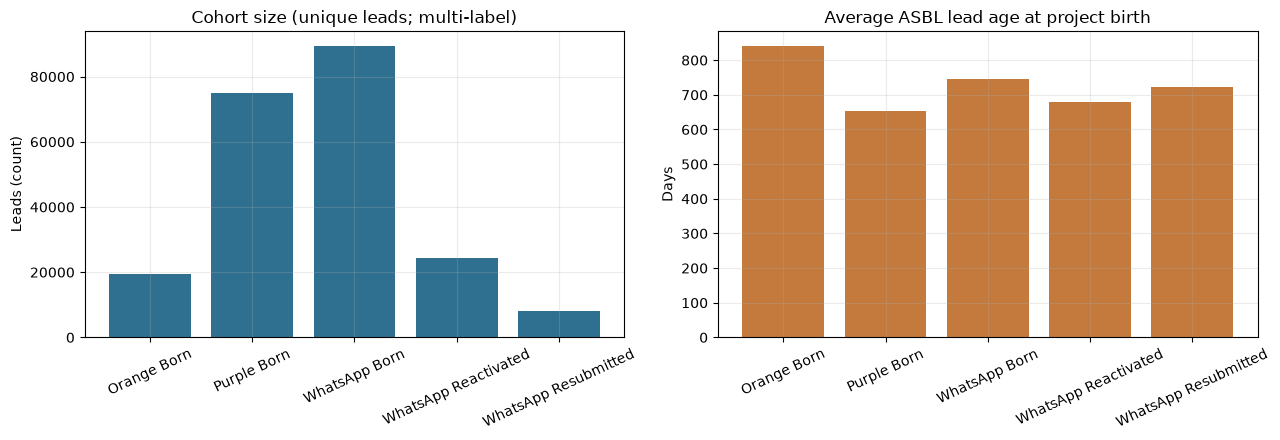

Saved outputs/figures/02_fresh_vs_cross.png


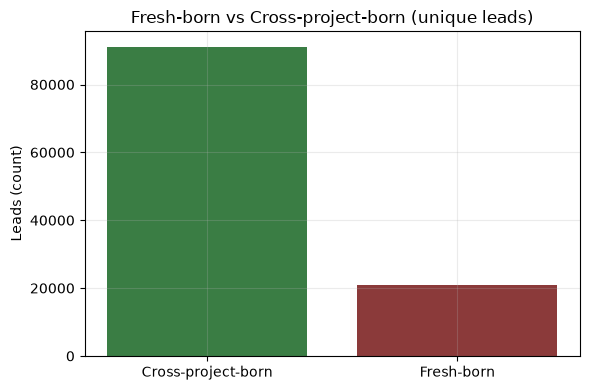

In [21]:
# Core analysis features (present + numeric)
CORE_FEATURES = [
    f
    for f in [
        "total_web_timespent",
        "total_session_count",
        "active_session_count",
        "avg_web_activity",
        "price_timespent",
        "home_timespent",
        "is_price_sheet_viewed",
        "is_site_visit_book_clicked",
        "total_call_duration",
        "total_answered_calls",
        "total_inbound_calls",
        "total_outbound_calls",
        "total_attempted_calls",
        "pickup_ratio",
        "episode_whatsapp_inbound_count",
        "has_whatsapp_inbound_in_episode",
        "days_to_first_whatsapp_inbound",
        "days_to_last_whatsapp_inbound",
        "episode_duration_days",
        "episode_stage_movement_count",
        "resubmission_count_in_episode",
        "is_resubmitted_in_episode",
        "did_reach_site_visit_in_episode",
        "is_reactivated_episode",
        "lead_age_at_episode_start_days",
        "lead_age_at_project_birth_days",
        "lead_age_months",
    ]
    if f in df_bi.columns
]

features = CORE_FEATURES
print("Features in analysis:", len(features))
for f in features:
    meta = METRIC_META.get(f, {})
    print(f"  • {f:40s} [{meta.get('unit','?')}]")

# --- Cohort profiling ---
lead_u = df_bi.drop_duplicates("lead")
cohort_profile_rows = []
for name, flag in COHORT_FLAG.items():
    sub = lead_u[lead_u[flag] == 1]
    cohort_profile_rows.append(
        {
            "Cohort": name,
            "Leads": int(len(sub)),
            "Fresh %": float((sub["is_fresh_born"] == 1).mean() * 100) if len(sub) else np.nan,
            "Cross-project %": float((sub["is_cross_project"] == 1).mean() * 100) if len(sub) else np.nan,
            "Avg ASBL Age (days)": float(sub["lead_age_asbl_days"].mean()) if "lead_age_asbl_days" in sub.columns else float(sub["lead_age_at_project_birth_days"].mean())
            if len(sub)
            else np.nan,
            "Median ASBL Age (days)": float(sub["lead_age_asbl_days"].median()) if "lead_age_asbl_days" in sub.columns else float(sub["lead_age_at_project_birth_days"].median())
            if len(sub)
            else np.nan,
            "Avg Episodes / Lead": float(
                df_bi.loc[df_bi[flag] == 1].groupby("lead")["episode_number"].max().mean()
            )
            if (df_bi[flag] == 1).any()
            else np.nan,
        }
    )
cohort_profile = pd.DataFrame(cohort_profile_rows)
print("\n=== Cohort profile (lead-level) ===")
display(round_df(cohort_profile))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(cohort_profile["Cohort"], cohort_profile["Leads"], color="#2F6F8F")
axes[0].set_title("Cohort size (unique leads; multi-label)")
axes[0].set_ylabel("Leads (count)")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(
    cohort_profile["Cohort"],
    cohort_profile["Avg ASBL Age (days)"],
    color="#C47A3D",
)
axes[1].set_title("Average ASBL lead age at project birth")
axes[1].set_ylabel("Days")
axes[1].tick_params(axis="x", rotation=25)
save_fig("01_cohort_profile.png")

# Fresh vs cross overall
fc_counts = lead_u["fresh_cross_status"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(fc_counts.index.astype(str), fc_counts.values, color=["#3A7D44", "#8B3A3A"])
ax.set_title("Fresh-born vs Cross-project-born (unique leads)")
ax.set_ylabel("Leads (count)")
save_fig("02_fresh_vs_cross.png")



## 12. Episode analysis (population means)

**Question:** What is average behavioural intensity by episode when zeros are included?

Primary = population mean. Active-user mean is secondary.


=== Episode sample sizes ===


,Episode,Unique Leads,Total Episodes
0,Episode 1,111946,111946
1,Episode 2,33940,33940
2,Episode 3,9895,9895
3,Episode 4,3770,3770
4,Episode 5+,1763,4884


=== Episode population averages (include zeros) — preview ===


,Feature,Episode 1,Episode 2,Episode 3,Episode 4,Episode 5+,Unit
0,total_web_timespent,126.99,252.17,279.26,325.45,"2,118.38",Seconds
1,total_session_count,1.77,1.91,1.95,2.12,14.69,Sessions
2,active_session_count,1.40,1.78,1.83,2.03,13.05,Sessions
3,avg_web_activity,81.63,137.52,149.22,137.73,141.21,Seconds / session
4,price_timespent,168.01,178.88,168.55,190.52,620.42,Seconds
5,home_timespent,60.94,82.85,99.28,119.35,902.64,Seconds
6,total_call_duration,50.59,52.06,67.20,74.02,62.17,Seconds
7,total_answered_calls,1.34,1.36,1.44,1.45,1.40,Calls
8,total_inbound_calls,1.34,1.35,1.38,1.36,1.36,Calls
9,total_outbound_calls,4.40,4.38,4.51,4.43,3.50,Calls


=== Episode-to-episode change (abs + %) ===


,Feature,Unit,Episode 1,Episode 2,Episode 3,Episode 4,Episode 5+,Abs Δ Episode 1→Episode 2,% Δ Episode 1→Episode 2,Abs Δ Episode 2→Episode 3,% Δ Episode 2→Episode 3,Abs Δ Episode 3→Episode 4,% Δ Episode 3→Episode 4,Abs Δ Episode 4→Episode 5+,% Δ Episode 4→Episode 5+,Overall Trend,pp Δ Episode 1→Episode 2,pp Δ Episode 2→Episode 3,pp Δ Episode 3→Episode 4,pp Δ Episode 4→Episode 5+
0,total_web_timespent,Seconds,126.99,252.17,279.26,325.45,"2,118.38",125.18,98.57%,27.09,10.74%,46.19,16.54%,"1,792.93",550.91%,Increasing,NaN,NaN,NaN,NaN
1,total_session_count,Sessions,1.77,1.91,1.95,2.12,14.69,0.14,7.91%,0.04,2.09%,0.17,8.72%,12.57,592.92%,Increasing,NaN,NaN,NaN,NaN
2,active_session_count,Sessions,1.40,1.78,1.83,2.03,13.05,0.38,27.14%,0.05,2.81%,0.20,10.93%,11.02,542.86%,Increasing,NaN,NaN,NaN,NaN
3,avg_web_activity,Seconds / session,81.63,137.52,149.22,137.73,141.21,55.89,68.47%,11.70,8.51%,-11.49,-7.70%,3.48,2.53%,Mixed,NaN,NaN,NaN,NaN
4,price_timespent,Seconds,168.01,178.88,168.55,190.52,620.42,10.87,6.47%,-10.33,-5.77%,21.97,13.03%,429.90,225.65%,Mixed,NaN,NaN,NaN,NaN
5,home_timespent,Seconds,60.94,82.85,99.28,119.35,902.64,21.91,35.95%,16.43,19.83%,20.07,20.22%,783.29,656.30%,Increasing,NaN,NaN,NaN,NaN
6,total_call_duration,Seconds,50.59,52.06,67.20,74.02,62.17,1.47,2.91%,15.14,29.08%,6.82,10.15%,-11.85,-16.01%,Mixed,NaN,NaN,NaN,NaN
7,total_answered_calls,Calls,1.34,1.36,1.44,1.45,1.40,0.02,1.49%,0.08,5.88%,0.01,0.69%,-0.05,-3.45%,Mixed,NaN,NaN,NaN,NaN
8,total_inbound_calls,Calls,1.34,1.35,1.38,1.36,1.36,0.01,0.75%,0.03,2.22%,-0.02,-1.45%,0.00,0.00%,Mixed,NaN,NaN,NaN,NaN
9,total_outbound_calls,Calls,4.40,4.38,4.51,4.43,3.50,-0.02,-0.45%,0.13,2.97%,-0.08,-1.77%,-0.93,-20.99%,Mixed,NaN,NaN,NaN,NaN


Saved outputs/figures/03_episode_feature_curves.png


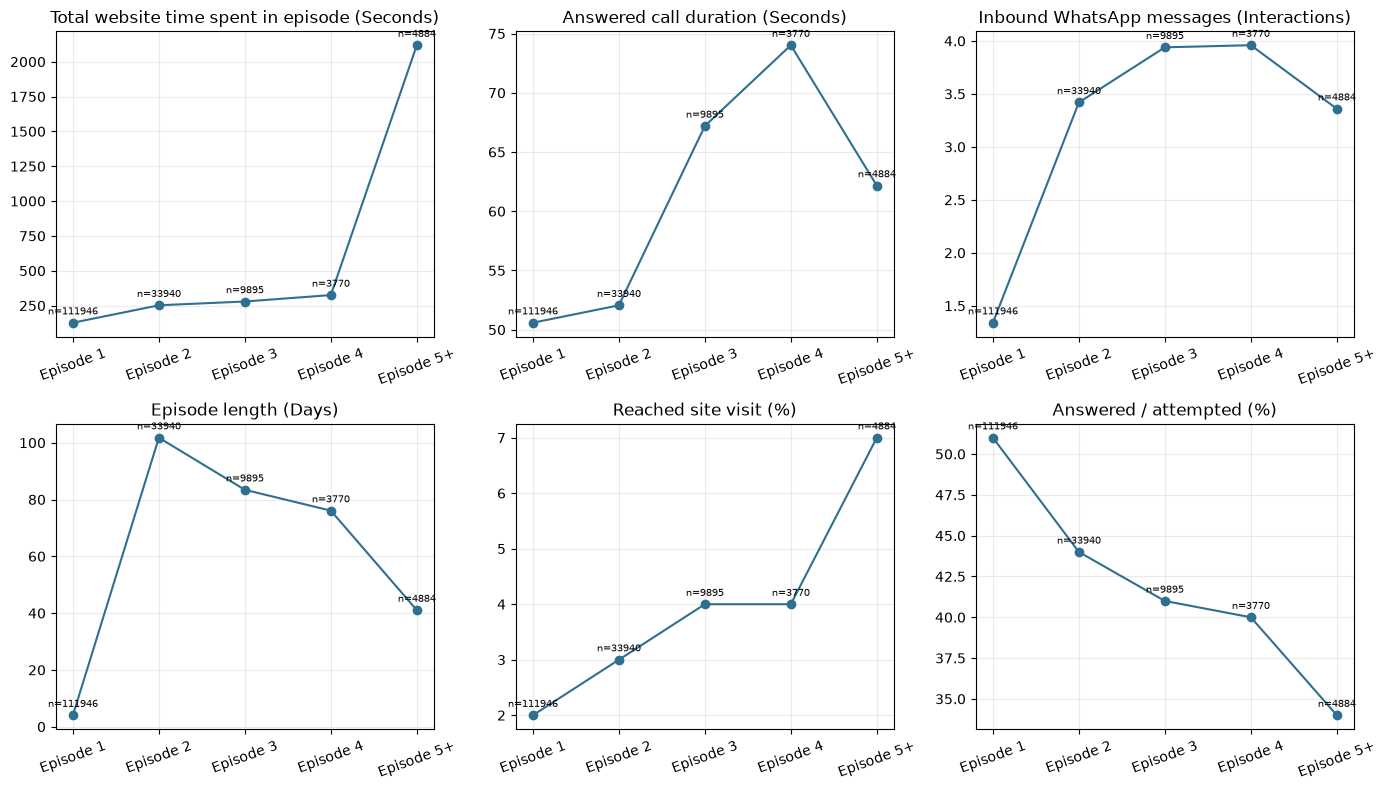

In [22]:

# ========== Episode analysis (population means, zeros included) ==========
episode_sample_size = episode_sample_size_table(df_bi)
print("=== Episode sample sizes ===")
display(round_df(episode_sample_size))

episode_avgs = episode_average_table(df_bi, features, how="population")
episode_avgs_active = episode_average_table(df_bi, features, how="active")
episode_change = episode_change_table(episode_avgs)

print("=== Episode population averages (include zeros) — preview ===")
display(round_df(episode_avgs).head(20))
print("=== Episode-to-episode change (abs + %) ===")
display(round_df(episode_change).head(20))

# Per-cohort episode averages
source_avgs = {}
for name, flag in COHORT_FLAG.items():
    sub = df_bi[df_bi[flag] == 1]
    if len(sub) >= MIN_SAMPLE_FLAG:
        source_avgs[name] = episode_average_table(sub, features, how="population")
    else:
        print(f"⚠ Skipping episode averages for {name}: n={len(sub)} episodes (< {MIN_SAMPLE_FLAG})")

# Key feature progression charts
KEY_PLOT = [
    f
    for f in [
        "total_web_timespent",
        "total_call_duration",
        "episode_whatsapp_inbound_count",
        "episode_duration_days",
        "did_reach_site_visit_in_episode",
        "pickup_ratio",
    ]
    if f in features
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, f in enumerate(KEY_PLOT):
    ax = axes[i]
    vals = [episode_avgs.loc[episode_avgs["Feature"] == f, ep].values[0] for ep in EPISODE_ORDER]
    if METRIC_META.get(f, {}).get("kind") == "rate":
        vals = [v * 100 if pd.notna(v) else np.nan for v in vals]
    ax.plot(EPISODE_ORDER, vals, marker="o", color="#2F6F8F")
    ax.set_title(axis_label(f))
    ax.tick_params(axis="x", rotation=20)
    ns = [episode_sample_size.loc[episode_sample_size["Episode"] == ep, "Total Episodes"].values[0] for ep in EPISODE_ORDER]
    for x, y, n in zip(EPISODE_ORDER, vals, ns):
        if pd.notna(y):
            ax.annotate(f"n={n}", (x, y), textcoords="offset points", xytext=(0, 6), fontsize=7, ha="center")
for j in range(len(KEY_PLOT), len(axes)):
    axes[j].axis("off")
save_fig("03_episode_feature_curves.png")

# When does change happen? largest abs % moves
change_highlights = []
for _, row in episode_change.iterrows():
    feat = row["Feature"]
    kind = METRIC_META.get(feat, {}).get("kind")
    for prev_ep, curr_ep in zip(EPISODE_ORDER, EPISODE_ORDER[1:]):
        abs_col = f"Abs Δ {prev_ep}→{curr_ep}"
        pct_col = f"% Δ {prev_ep}→{curr_ep}"
        if abs_col not in row:
            continue
        abs_chg = row[abs_col]
        if pd.isna(abs_chg):
            continue
        n_curr = int(episode_sample_size.loc[episode_sample_size["Episode"] == curr_ep, "Total Episodes"].values[0])
        change_highlights.append(
            {
                "Feature": feat,
                "Transition": f"{prev_ep} → {curr_ep}",
                "Previous": row[prev_ep],
                "Current": row[curr_ep],
                "Absolute change": abs_chg,
                "Relative change": row[pct_col],
                "Unit": row["Unit"],
                "n_current_episode": n_curr,
                "unstable": n_curr < MIN_SAMPLE_FLAG,
            }
        )
change_hl_df = pd.DataFrame(change_highlights)
# Rank by |relative| where numeric
def _rel_num(x):
    if isinstance(x, str) and x.endswith("%"):
        try:
            return abs(float(x.replace("%", "")))
        except Exception:
            return -1
    return -1

change_hl_df["rel_rank"] = change_hl_df["Relative change"].map(_rel_num)
stable = change_hl_df[~change_hl_df["unstable"]].copy()


## 13. Within-lead behavioural change

**Question:** For the same lead, how do consecutive episodes differ?

Separates composition effects from true within-lead change.


In [23]:
# ========== Within-lead behavioural change ==========
print("Building within-lead consecutive episode pairs...")
ep = df_bi.sort_values(["lead", "episode_number"]).copy()
ep["lead_clean"] = ep["lead"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
curr = ep[ep["episode_number"] >= 2].copy()
curr["prev_episode_number"] = curr["episode_number"] - 1
pairs = curr.merge(
    ep,
    left_on=["lead_clean", "prev_episode_number"],
    right_on=["lead_clean", "episode_number"],
    suffixes=("_curr", "_prev"),
)
print(f"Within-lead pairs: {len(pairs):,}")

pair_labels = {2: "Ep2 vs Ep1", 3: "Ep3 vs Ep2", 4: "Ep4 vs Ep3"}


def label_pair(n):
    n = int(n)
    return pair_labels.get(n, "Ep5+ vs prior")


within_rows = []
for f in features:
    prev_col, curr_col = f"{f}_prev", f"{f}_curr"
    if prev_col not in pairs.columns or curr_col not in pairs.columns:
        continue
    for pair_name, sub in pairs.groupby(pairs["episode_number_curr"].map(label_pair)):
        prev = pd.to_numeric(sub[prev_col], errors="coerce").fillna(0.0)
        curr_v = pd.to_numeric(sub[curr_col], errors="coerce").fillna(0.0)
        if len(prev) == 0:
            continue
        delta = curr_v - prev
        prev_avg = population_mean(prev, f)
        curr_avg = population_mean(curr_v, f)
        abs_chg, pct_lab, _ = pct_change_safe(prev_avg, curr_avg)
        p_val = 1.0
        try:
            if len(prev) > 1 and not (delta == 0).all():
                p_val = float(stats.ttest_rel(curr_v, prev).pvalue)
        except Exception:
            p_val = 1.0
        kind = METRIC_META.get(f, {}).get("kind")
        within_rows.append(
            {
                "pair": pair_name,
                "feature": f,
                "unit": METRIC_META.get(f, {}).get("unit", ""),
                "n_pairs": int(len(prev)),
                "previous_avg": prev_avg,
                "current_avg": curr_avg,
                "absolute_change": abs_chg,
                "pct_change": pct_lab,
                "pp_change": (abs_chg * 100) if kind == "rate" and pd.notna(abs_chg) else np.nan,
                "pct_increased": float((delta > 0).mean() * 100),
                "pct_decreased": float((delta < 0).mean() * 100),
                "pct_unchanged": float((delta == 0).mean() * 100),
                "p_value": p_val,
                "significant_p05": p_val < 0.05,
                "unstable_sample": len(prev) < MIN_SAMPLE_FLAG,
            }
        )

within_lead_pairs = pd.DataFrame(within_rows)
print("=== Within-lead change (population means on paired leads) ===")
display(round_df(within_lead_pairs).head(30))

# Contrast population vs within-lead for key features
contrast_rows = []
for f in KEY_PLOT:
    pop = episode_change[episode_change["Feature"] == f]
    win = within_lead_pairs[(within_lead_pairs["feature"] == f) & (within_lead_pairs["pair"] == "Ep2 vs Ep1")]
    if pop.empty or win.empty:
        continue
    contrast_rows.append(
        {
            "Feature": f,
            "Unit": METRIC_META.get(f, {}).get("unit", ""),
            "Population Ep1": pop.iloc[0]["Episode 1"],
            "Population Ep2": pop.iloc[0]["Episode 2"],
            "Population Abs Δ": pop.iloc[0].get("Abs Δ Episode 1→Episode 2"),
            "Population % Δ": pop.iloc[0].get("% Δ Episode 1→Episode 2"),
            "Within-lead Ep1": win.iloc[0]["previous_avg"],
            "Within-lead Ep2": win.iloc[0]["current_avg"],
            "Within Abs Δ": win.iloc[0]["absolute_change"],
            "Within % Δ": win.iloc[0]["pct_change"],
            "Within n pairs": win.iloc[0]["n_pairs"],
        }
    )
contrast_df = pd.DataFrame(contrast_rows)
print("=== Population vs within-lead (Ep2 vs Ep1) — interpretation critical ===")
display(round_df(contrast_df))



Building within-lead consecutive episode pairs...
Within-lead pairs: 52,489
=== Within-lead change (population means on paired leads) ===


,pair,feature,unit,n_pairs,previous_avg,current_avg,absolute_change,pct_change,pp_change,pct_increased,pct_decreased,pct_unchanged,p_value,significant_p05,unstable_sample
0,Ep2 vs Ep1,total_web_timespent,Seconds,33940,130.23,252.17,121.94,93.63%,NaN,12.11,9.46,78.42,0.00,True,False
1,Ep3 vs Ep2,total_web_timespent,Seconds,9895,292.02,279.26,-12.76,-4.37%,NaN,13.39,18.26,68.35,0.43,False,False
2,Ep4 vs Ep3,total_web_timespent,Seconds,3770,316.97,325.45,8.48,2.68%,NaN,15.17,19.63,65.20,0.90,False,False
3,Ep5+ vs prior,total_web_timespent,Seconds,4884,"1,890.71","2,118.38",227.67,12.04%,NaN,21.58,23.53,54.89,0.74,False,False
4,Ep2 vs Ep1,total_session_count,Sessions,33940,1.79,1.91,0.12,6.70%,NaN,12.52,10.32,77.17,0.00,True,False
5,Ep3 vs Ep2,total_session_count,Sessions,9895,1.98,1.95,-0.03,-1.52%,NaN,13.10,17.81,69.10,0.12,False,False
6,Ep4 vs Ep3,total_session_count,Sessions,3770,2.25,2.12,-0.13,-5.78%,NaN,14.27,19.15,66.58,0.95,False,False
7,Ep5+ vs prior,total_session_count,Sessions,4884,12.30,14.69,2.39,19.43%,NaN,21.40,22.24,56.37,0.17,False,False
8,Ep2 vs Ep1,active_session_count,Sessions,33940,1.41,1.78,0.37,26.24%,NaN,11.64,8.93,79.44,0.00,True,False
9,Ep3 vs Ep2,active_session_count,Sessions,9895,1.89,1.83,-0.06,-3.17%,NaN,12.45,17.04,70.51,0.10,False,False


=== Population vs within-lead (Ep2 vs Ep1) — interpretation critical ===


,Feature,Unit,Population Ep1,Population Ep2,Population Abs Δ,Population % Δ,Within-lead Ep1,Within-lead Ep2,Within Abs Δ,Within % Δ,Within n pairs
0,total_web_timespent,Seconds,126.99,252.17,125.18,98.57%,130.23,252.17,121.94,93.63%,33940
1,total_call_duration,Seconds,50.59,52.06,1.47,2.91%,77.67,52.06,-25.61,-32.97%,33940
2,episode_whatsapp_inbound_count,Interactions,1.34,3.42,2.08,155.22%,1.43,3.42,1.99,139.16%,33940
3,episode_duration_days,Days,4.04,101.77,97.73,2419.06%,4.67,101.77,97.10,2079.23%,33940
4,did_reach_site_visit_in_episode,Rate (0-1) → display %,0.02,0.03,0.01,50.00%,0.03,0.03,0.00,0.00%,33940
5,pickup_ratio,Rate (0-1) → display %,0.51,0.44,-0.07,-13.73%,0.49,0.44,-0.05,-10.20%,33940


## 14. Fresh vs Cross-project comparison

**Question:** Do fresh-born leads behave differently from cross-project-born leads?


=== Fresh vs Cross-project — population episode means ===


,Status,Episodes,Leads,Avg ASBL Age (days),total_web_timespent,total_session_count,active_session_count,avg_web_activity,price_timespent,home_timespent,total_call_duration,total_answered_calls,total_inbound_calls,total_outbound_calls,total_attempted_calls,pickup_ratio,episode_whatsapp_inbound_count,has_whatsapp_inbound_in_episode,days_to_first_whatsapp_inbound,days_to_last_whatsapp_inbound,episode_duration_days,episode_stage_movement_count,resubmission_count_in_episode,is_resubmitted_in_episode,did_reach_site_visit_in_episode,is_reactivated_episode,lead_age_at_episode_start_days,lead_age_at_project_birth_days,lead_age_months
0,Cross-project-born,131996,91114,757.54,298.68,2.11,1.97,132.65,205.20,106.22,59.46,1.38,1.33,4.40,3.25,0.48,2.92,0.22,34.97,48.75,9.63,2.38,1.43,0.09,0.03,0.31,283.77,323.07,9.32
1,Fresh-born,32439,20832,593.32,73.02,1.44,1.35,52.00,121.60,43.18,37.04,1.47,1.38,3.47,2.62,0.47,1.81,0.64,10.23,13.05,12.76,2.25,1.23,0.06,0.01,0.36,0.36,0.00,0.01


=== Fresh vs Cross statistical comparison ===


,Feature,Unit,Fresh mean,Cross-project mean,Absolute difference (Cross − Fresh),Relative difference,pp difference,n_fresh_episodes,n_cross_episodes,test,p_value,significant_p05,practically_notable
0,total_web_timespent,Seconds,68.34,"4,081.60","4,013.26",5872.87%,NaN,32439,131996,Mann-Whitney U,0.04,True,True
1,total_call_duration,Seconds,44.43,78.18,33.75,75.95%,NaN,32439,131996,Mann-Whitney U,0.00,True,True
2,episode_whatsapp_inbound_count,Interactions,1.56,0.79,-0.77,-49.23%,NaN,32439,131996,Mann-Whitney U,0.00,True,True
3,episode_duration_days,Days,61.19,48.16,-13.03,-21.29%,NaN,32439,131996,Mann-Whitney U,0.13,False,True
4,did_reach_site_visit_in_episode,Rate (0-1) → display %,0.01,0.03,0.01,105.08%,1.33,32439,131996,Mann-Whitney U,0.00,True,True
5,pickup_ratio,Rate (0-1) → display %,0.47,0.48,0.01,2.43%,1.15,32439,131996,Mann-Whitney U,0.00,True,False


Saved outputs/figures/04_fresh_vs_cross_features.png


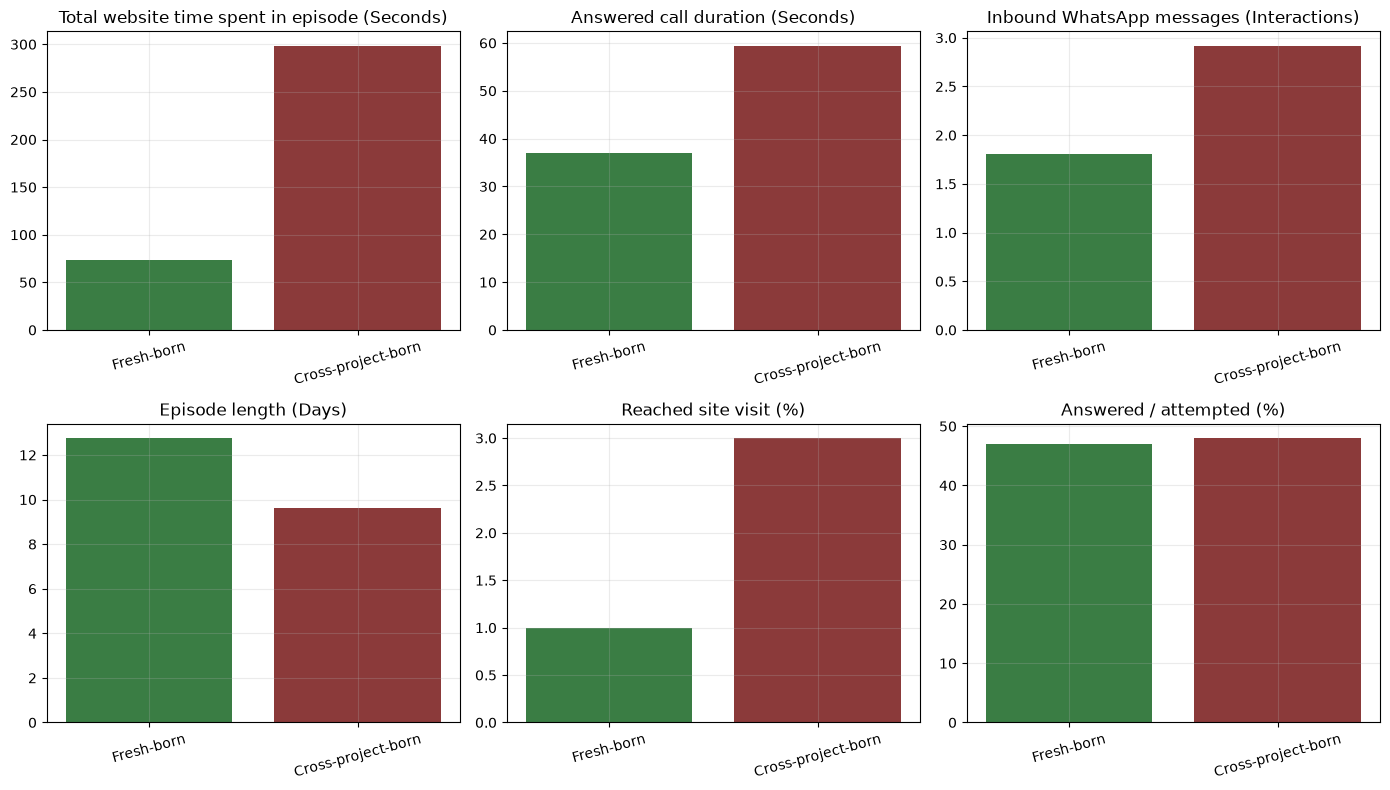

In [24]:
# ========== Fresh vs Cross-project comparison ==========
fc_rows = []
for status, sub in df_bi.groupby("fresh_cross_status"):
    leads = sub.drop_duplicates("lead")
    row = {
        "Status": status,
        "Episodes": int(len(sub)),
        "Leads": int(leads["lead"].nunique()),
        "Avg ASBL Age (days)": float(leads["lead_age_asbl_days"].mean()) if "lead_age_asbl_days" in leads.columns else float(leads["lead_age_at_project_birth_days"].mean()),
    }
    for f in features:
        row[f] = population_mean(sub[f], f)
    fc_rows.append(row)
fresh_cross_comparison = pd.DataFrame(fc_rows)
print("=== Fresh vs Cross-project — population episode means ===")
display(round_df(fresh_cross_comparison))

# Statistical tests fresh vs cross on key metrics (episode-level)
stat_rows = []
fresh_ep = df_bi[df_bi["is_fresh_born"] == 1]
cross_ep = df_bi[df_bi["is_cross_project"] == 1]
for f in KEY_PLOT:
    a = pd.to_numeric(fresh_ep[f], errors="coerce").fillna(0.0)
    b = pd.to_numeric(cross_ep[f], errors="coerce").fillna(0.0)
    if len(a) < 2 or len(b) < 2:
        continue
    try:
        # Mann-Whitney: distribution-free, association language only
        u = stats.mannwhitneyu(a, b, alternative="two-sided")
        p = float(u.pvalue)
    except Exception:
        p = 1.0
    ma, mb = float(a.mean()), float(b.mean())
    abs_chg, pct_lab, _ = pct_change_safe(ma, mb)
    kind = METRIC_META.get(f, {}).get("kind")
    stat_rows.append(
        {
            "Feature": f,
            "Unit": METRIC_META.get(f, {}).get("unit", ""),
            "Fresh mean": ma,
            "Cross-project mean": mb,
            "Absolute difference (Cross − Fresh)": abs_chg if ma == ma else mb - ma,
            "Relative difference": pct_lab,
            "pp difference": ((mb - ma) * 100) if kind == "rate" else np.nan,
            "n_fresh_episodes": int(len(a)),
            "n_cross_episodes": int(len(b)),
            "test": "Mann-Whitney U",
            "p_value": p,
            "significant_p05": p < 0.05,
            "practically_notable": abs(mb - ma) > (0.1 * abs(ma) if ma != 0 else abs(mb) > 0),
        }
    )
fresh_cross_stats = pd.DataFrame(stat_rows)
print("=== Fresh vs Cross statistical comparison ===")
display(round_df(fresh_cross_stats))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, f in enumerate(KEY_PLOT):
    ax = axes[i]
    means = []
    labels = []
    for status in ["Fresh-born", "Cross-project-born"]:
        part = fresh_cross_comparison[fresh_cross_comparison["Status"] == status]
        if part.empty or f not in part.columns:
            continue
        v = part.iloc[0][f]
        if METRIC_META.get(f, {}).get("kind") == "rate" and pd.notna(v):
            v = v * 100
        means.append(v)
        labels.append(status)
    ax.bar(labels, means, color=["#3A7D44", "#8B3A3A"])
    ax.set_title(axis_label(f))
    ax.tick_params(axis="x", rotation=15)
for j in range(len(KEY_PLOT), len(axes)):
    axes[j].axis("off")
save_fig("04_fresh_vs_cross_features.png")



## 15. Lead age × engagement and age × cohort

**Question:** Does actual ASBL lead age help explain cohort differences?


Saved outputs/figures/05_lead_age_distribution.png


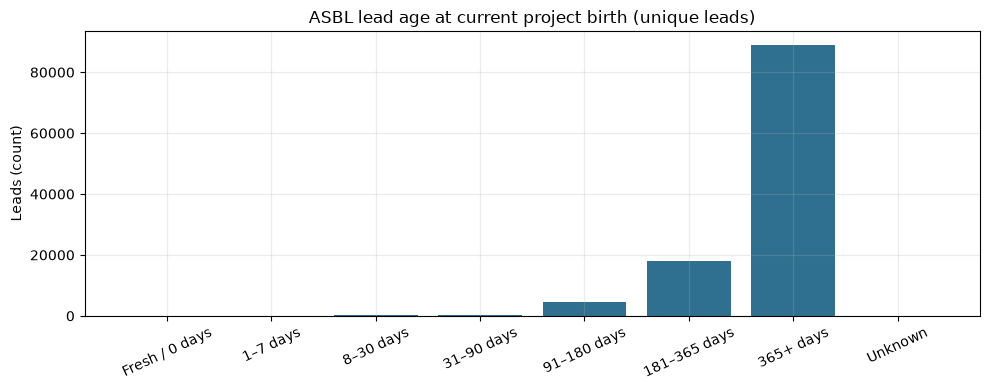

=== Behaviour by lead-age bucket (population means) ===


,Age bucket,n_episodes,n_leads,total_web_timespent,total_call_duration,episode_whatsapp_inbound_count,episode_duration_days,did_reach_site_visit_in_episode,pickup_ratio
0,Fresh / 0 days,3193,3193,125.52,54.33,1.57,62.18,0.00,0.37
1,1–7 days,43676,30683,111.05,43.63,1.89,11.35,0.02,0.48
2,8–30 days,12088,10322,233.32,48.71,3.13,27.61,0.02,0.48
3,31–90 days,17833,14792,248.63,43.08,3.03,8.35,0.02,0.49
4,91–180 days,17935,14695,298.84,45.01,2.78,7.18,0.02,0.50
5,181–365 days,25640,20876,390.89,47.28,2.78,6.44,0.02,0.49
6,365+ days,44070,31332,502.11,82.76,2.72,11.25,0.03,0.48


Saved outputs/figures/06_age_x_engagement.png


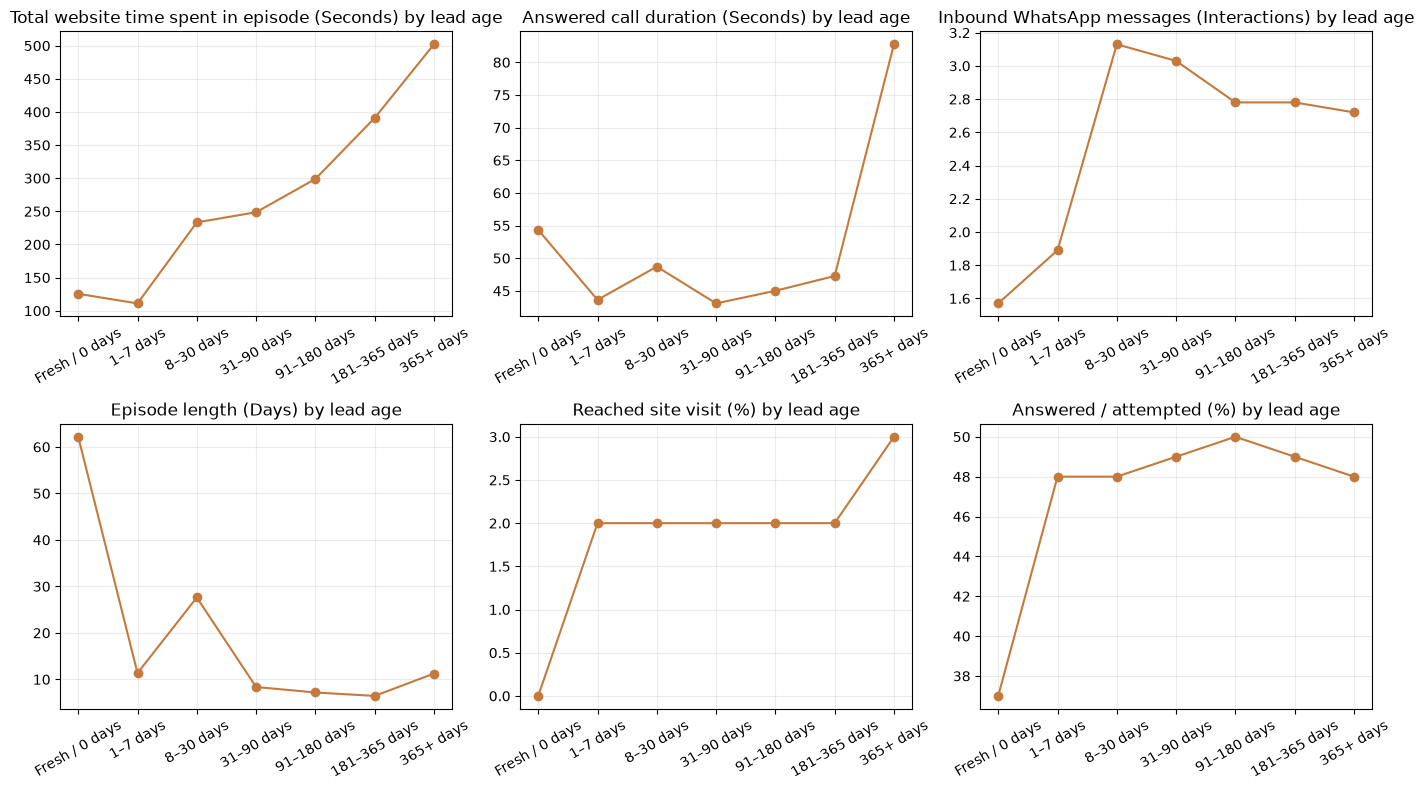

=== Lead age × cohort (flag unstable cells) ===


,Cohort,Age bucket,n_episodes,Avg web time (seconds),Avg call duration (seconds),Avg WA interactions,Site visit rate,unstable
0,Orange Born,Fresh / 0 days,88,558.76,136.89,1.77,0.00,False
1,Orange Born,1–7 days,7065,179.06,69.94,5.71,0.04,False
2,Orange Born,8–30 days,3041,298.72,77.70,5.40,0.04,False
3,Orange Born,31–90 days,3901,266.96,78.36,4.78,0.04,False
4,Orange Born,91–180 days,4262,337.36,92.47,4.53,0.04,False
5,Orange Born,181–365 days,5750,436.48,96.58,3.99,0.05,False
6,Orange Born,365+ days,12376,642.82,139.54,3.94,0.05,False
8,Purple Born,Fresh / 0 days,282,382.86,56.98,1.85,0.00,False
9,Purple Born,1–7 days,22702,109.40,44.61,3.12,0.03,False
10,Purple Born,8–30 days,7500,246.80,51.01,3.68,0.03,False


=== Lead age vs multi-episode / WA react / resub rates ===


,Age bucket,leads,multi_ep_rate,wa_react_rate,wa_resub_rate
0,181–365 days,17912,0.25,0.21,0.02
1,1–7 days,41,0.00,0.00,0.00
2,31–90 days,296,0.16,0.12,0.01
3,365+ days,88981,0.32,0.22,0.09
4,8–30 days,199,0.10,0.09,0.01
5,91–180 days,4517,0.24,0.21,0.02


In [25]:
# ========== Lead age analysis + age × cohort ==========
age_dist = (
    df_bi.drop_duplicates("lead")["lead_age_bucket"]
    .value_counts()
    .reindex(AGE_BUCKET_ORDER)
    .fillna(0)
    .astype(int)
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(age_dist.index.astype(str), age_dist.values, color="#2F6F8F")
ax.set_title("Lead age bucket distribution (unique leads, age at episode-1 proxy via lead-level birth age)")
# Use project-birth age for lead-level chart
lead_age_b = df_bi.drop_duplicates("lead").copy()
lead_age_b["bucket_at_birth"] = lead_age_b["lead_age_asbl_days"].apply(assign_lead_age_bucket)
age_dist2 = lead_age_b["bucket_at_birth"].value_counts().reindex(AGE_BUCKET_ORDER).fillna(0).astype(int)
ax.clear()
ax.bar([str(x) for x in age_dist2.index], age_dist2.values, color="#2F6F8F")
ax.set_title("ASBL lead age at current project birth (unique leads)")
ax.set_ylabel("Leads (count)")
ax.tick_params(axis="x", rotation=25)
save_fig("05_lead_age_distribution.png")

# Engagement by age bucket (episode population means)
age_feat_rows = []
for bucket in AGE_BUCKET_ORDER:
    sub = df_bi[df_bi["lead_age_bucket"].astype(str) == bucket]
    if len(sub) < MIN_SAMPLE_FLAG:
        continue
    row = {"Age bucket": bucket, "n_episodes": int(len(sub)), "n_leads": int(sub["lead"].nunique())}
    for f in KEY_PLOT:
        row[f] = population_mean(sub[f], f)
    age_feat_rows.append(row)
age_engagement = pd.DataFrame(age_feat_rows)
print("=== Behaviour by lead-age bucket (population means) ===")
display(round_df(age_engagement))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, f in enumerate(KEY_PLOT):
    ax = axes[i]
    if f not in age_engagement.columns:
        ax.axis("off")
        continue
    y = age_engagement[f].tolist()
    if METRIC_META.get(f, {}).get("kind") == "rate":
        y = [v * 100 if pd.notna(v) else np.nan for v in y]
    ax.plot(age_engagement["Age bucket"], y, marker="o", color="#C47A3D")
    ax.set_title(axis_label(f) + " by lead age")
    ax.tick_params(axis="x", rotation=30)
for j in range(len(KEY_PLOT), len(axes)):
    axes[j].axis("off")
save_fig("06_age_x_engagement.png")

# Age × cohort heatmap-style table for web time
age_cohort_rows = []
for name, flag in COHORT_FLAG.items():
    for bucket in AGE_BUCKET_ORDER:
        sub = df_bi[(df_bi[flag] == 1) & (df_bi["lead_age_bucket"].astype(str) == bucket)]
        n = len(sub)
        age_cohort_rows.append(
            {
                "Cohort": name,
                "Age bucket": bucket,
                "n_episodes": n,
                "Avg web time (seconds)": population_mean(sub["total_web_timespent"], "total_web_timespent")
                if n
                else np.nan,
                "Avg call duration (seconds)": population_mean(sub["total_call_duration"], "total_call_duration")
                if n and "total_call_duration" in sub.columns
                else np.nan,
                "Avg WA interactions": population_mean(
                    sub["episode_whatsapp_inbound_count"], "episode_whatsapp_inbound_count"
                )
                if n and "episode_whatsapp_inbound_count" in sub.columns
                else np.nan,
                "Site visit rate": population_mean(
                    sub["did_reach_site_visit_in_episode"], "did_reach_site_visit_in_episode"
                )
                if n and "did_reach_site_visit_in_episode" in sub.columns
                else np.nan,
                "unstable": n < MIN_SAMPLE_FLAG,
            }
        )
age_cohort = pd.DataFrame(age_cohort_rows)
print("=== Lead age × cohort (flag unstable cells) ===")
display(round_df(age_cohort[~age_cohort["unstable"]]).head(40))

# Does lead age associate with reactivation / resubmission tendency?
lead_u2 = df_bi.drop_duplicates("lead").copy()
lead_u2["max_episode"] = df_bi.groupby("lead")["episode_number"].transform("max")
# fix: recompute properly
max_ep = df_bi.groupby("lead_clean")["episode_number"].max().rename("max_episode")
lead_u2 = df_bi.drop_duplicates("lead_clean").merge(max_ep, on="lead_clean", how="left")
lead_u2["has_multi_episode"] = (lead_u2["max_episode"] >= 2).astype(int)
age_react = (
    lead_u2.groupby(lead_u2["lead_age_asbl_days"].apply(assign_lead_age_bucket), observed=False)
    .agg(leads=("lead_clean", "nunique"), multi_ep_rate=("has_multi_episode", "mean"), wa_react_rate=("is_whatsapp_reactivated", "mean"), wa_resub_rate=("is_whatsapp_resubmitted", "mean"))
    .reset_index()
    .rename(columns={"lead_age_asbl_days": "Age bucket"})
)
print("=== Lead age vs multi-episode / WA react / resub rates ===")
display(round_df(age_react))



## 16. Cohort / episode summaries, special behaviour, business insights

**Question:** What is different, when, for whom, and what should the business notice?


In [26]:
# Cohort comparison summary + special behaviour + drivers + DOCX + Excel
# --- Cohort comparison summary table ---
summary_rows = []
for name, flag in COHORT_FLAG.items():
    sub = df_bi[df_bi[flag] == 1]
    leads = sub.drop_duplicates("lead")
    row = {
        "Metric\\Cohort": name,
        "Leads": int(leads["lead"].nunique()),
        "Episodes": int(len(sub)),
        "Fresh %": float((leads["is_fresh_born"] == 1).mean() * 100) if len(leads) else np.nan,
        "Cross-project %": float((leads["is_cross_project"] == 1).mean() * 100) if len(leads) else np.nan,
        "Avg ASBL Age (days)": float(leads["lead_age_asbl_days"].mean()) if "lead_age_asbl_days" in leads.columns else float(leads["lead_age_at_project_birth_days"].mean()) if len(leads) else np.nan,
    }
    for f, label in [
        ("total_web_timespent", "Avg Web Time (seconds)"),
        ("total_call_duration", "Avg Call Duration (seconds)"),
        ("episode_whatsapp_inbound_count", "Avg WhatsApp Interactions"),
        ("episode_duration_days", "Avg Episode Duration (days)"),
        ("did_reach_site_visit_in_episode", "Site Visit Rate"),
        ("is_reactivated_episode", "Reactivation Rate (episode has successor)"),
        ("is_resubmitted_in_episode", "Resubmission Rate"),
        ("pickup_ratio", "Pickup Ratio"),
    ]:
        if f in sub.columns:
            v = population_mean(sub[f], f)
            if METRIC_META.get(f, {}).get("kind") == "rate" and pd.notna(v):
                row[label] = v * 100  # store as %
            else:
                row[label] = v
    summary_rows.append(row)

cohort_comparison_summary = pd.DataFrame(summary_rows).set_index("Metric\\Cohort").T
print("=== Cohort comparison summary (units in row labels; rates as %) ===")
display(round_df(cohort_comparison_summary))

# Episode comparison summary overall
ep_summary_cols = ["Feature", "Unit"] + EPISODE_ORDER + ["Overall Trend"]
episode_comparison_summary = episode_change[
    [c for c in ep_summary_cols if c in episode_change.columns]
].copy()
print("=== Episode comparison summary (overall) ===")
display(round_df(episode_comparison_summary).head(25))

# Per-cohort episode summaries where sample allows
cohort_episode_summaries = {}
for name, tbl in source_avgs.items():
    cohort_episode_summaries[name] = episode_change_table(tbl)

# Born vs Reactivated/Resubmitted split
born_mask = (df_bi["is_orange_born"] == 1) | (df_bi["is_purple_born"] == 1) | (df_bi["is_whatsapp_born"] == 1)
react_mask = df_bi["is_whatsapp_reactivated"] == 1
resub_mask = df_bi["is_whatsapp_resubmitted"] == 1
born_vs_recycle = pd.DataFrame(
    [
        {
            "Group": gname,
            "Leads": int(df_bi.loc[mask].drop_duplicates("lead")["lead"].nunique()),
            "Episodes": int(mask.sum()),
            **{
                f: population_mean(df_bi.loc[mask, f], f)
                for f in KEY_PLOT
                if f in df_bi.columns
            },
        }
        for gname, mask in [
            ("Born cohorts (Orange/Purple/WA born)", born_mask),
            ("WhatsApp Reactivated", react_mask),
            ("WhatsApp Resubmitted", resub_mask),
        ]
    ]
)
print("=== Born vs Reactivated vs Resubmitted ===")
display(round_df(born_vs_recycle))

# --- Special / unique behaviour detection ---
special_findings = []

# 1) Cohort with highest/lowest engagement on key metrics
for f in KEY_PLOT:
    scores = []
    for name, flag in COHORT_FLAG.items():
        sub = df_bi[df_bi[flag] == 1]
        if len(sub) < MIN_SAMPLE_FLAG:
            continue
        scores.append((name, population_mean(sub[f], f), len(sub)))
    if len(scores) < 2:
        continue
    scores = sorted(scores, key=lambda x: (x[1] if pd.notna(x[1]) else -np.inf))
    lo, hi = scores[0], scores[-1]
    if pd.isna(lo[1]) or pd.isna(hi[1]) or lo[1] == hi[1]:
        continue
    abs_chg, pct_lab, _ = pct_change_safe(lo[1], hi[1])
    special_findings.append(
        {
            "type": "cohort_extremes",
            "feature": f,
            "finding": (
                f"{hi[0]} has the highest average {f} at {format_value(f, hi[1])} "
                f"(n={hi[2]}); {lo[0]} is lowest at {format_value(f, lo[1])} (n={lo[2]}). "
                f"Gap: {format_value(f, abs_chg) if pd.notna(abs_chg) else 'n/a'} / relative {pct_lab}."
            ),
        }
    )

# 2) Sharpest episode drop/rise
if not stable.empty:
    top = stable.sort_values("rel_rank", ascending=False).head(5)
    for _, r in top.iterrows():
        special_findings.append(
            {
                "type": "episode_shift",
                "feature": r["Feature"],
                "finding": (
                    f"{r['Feature']} changes most at {r['Transition']}: "
                    f"{format_value(r['Feature'], r['Previous'])} → {format_value(r['Feature'], r['Current'])} "
                    f"(abs {r['Absolute change']}, relative {r['Relative change']}, n={r['n_current_episode']})."
                ),
            }
        )

# 3) Fresh vs cross divergence
for _, r in fresh_cross_stats.iterrows():
    if r.get("significant_p05") and r.get("practically_notable") and not (
        r["n_fresh_episodes"] < MIN_SAMPLE_FLAG or r["n_cross_episodes"] < MIN_SAMPLE_FLAG
    ):
        special_findings.append(
            {
                "type": "fresh_vs_cross",
                "feature": r["Feature"],
                "finding": (
                    f"Fresh vs cross-project differ on {r['Feature']}: "
                    f"Fresh {format_value(r['Feature'], r['Fresh mean'])} vs "
                    f"Cross {format_value(r['Feature'], r['Cross-project mean'])} "
                    f"(relative {r['Relative difference']}, Mann-Whitney p={r['p_value']:.4g}). "
                    f"This is associated with prior ASBL presence, not proven causal."
                ),
            }
        )

special_df = pd.DataFrame(special_findings)
print(f"=== Special / notable patterns detected: {len(special_df)} ===")
display(round_df(special_df) if hasattr(special_df, 'select_dtypes') else special_df)

# Business insight bullets (evidence-based language)
insights = []
if not cohort_profile.empty:
    richest = cohort_profile.sort_values("Leads", ascending=False).iloc[0]
    insights.append(
        f"Largest cohort by lead count is {richest['Cohort']} with {int(richest['Leads']):,} leads "
        f"({richest['Fresh %']:.1f}% fresh-born, avg ASBL age at project birth "
        f"{richest['Avg ASBL Age (days)']:.1f} days)."
    )
if not contrast_df.empty:
    insights.append(
        "Population-level episode averages and within-lead paired changes can diverge — "
        "use within-lead results to judge true behavioural change for the same person."
    )
if not fresh_cross_stats.empty and fresh_cross_stats["significant_p05"].any():
    insights.append(
        "Fresh-born and cross-project-born leads show statistically detectable differences on at least one key metric; "
        "interpret as association with lead maturity / prior ASBL presence."
    )
if not age_engagement.empty and "total_web_timespent" in age_engagement.columns:
    insights.append(
        "Lead-age buckets show variation in web engagement; older ASBL leads do not automatically mirror project-level 'new' behaviour."
    )

print("\n=== Key business takeaways (draft) ===")
for i, t in enumerate(insights, 1):
    print(f"{i}. {t}")



=== Cohort comparison summary (units in row labels; rates as %) ===


Metric\Cohort,Orange Born,Purple Born,WhatsApp Born,WhatsApp Reactivated,WhatsApp Resubmitted
Leads,"19,464.00","75,067.00","89,423.00","24,350.00","8,138.00"
Episodes,"36,483.00","111,187.00","110,110.00","62,058.00","13,113.00"
Fresh %,9.84,10.13,11.58,39.08,14.33
Cross-project %,90.16,89.87,88.42,60.92,85.67
Avg ASBL Age (days),841.24,652.95,745.95,680.64,721.48
Avg Web Time (seconds),342.81,228.41,255.89,211.62,549.12
Avg Call Duration (seconds),101.90,50.93,50.01,54.21,49.85
Avg WhatsApp Interactions,4.80,3.41,1.31,3.14,3.62
Avg Episode Duration (days),22.45,9.18,5.74,37.58,9.73
Site Visit Rate,5.00,2.00,2.00,3.00,3.00


=== Episode comparison summary (overall) ===


,Feature,Unit,Episode 1,Episode 2,Episode 3,Episode 4,Episode 5+,Overall Trend
0,total_web_timespent,Seconds,126.99,252.17,279.26,325.45,"2,118.38",Increasing
1,total_session_count,Sessions,1.77,1.91,1.95,2.12,14.69,Increasing
2,active_session_count,Sessions,1.40,1.78,1.83,2.03,13.05,Increasing
3,avg_web_activity,Seconds / session,81.63,137.52,149.22,137.73,141.21,Mixed
4,price_timespent,Seconds,168.01,178.88,168.55,190.52,620.42,Mixed
5,home_timespent,Seconds,60.94,82.85,99.28,119.35,902.64,Increasing
6,total_call_duration,Seconds,50.59,52.06,67.20,74.02,62.17,Mixed
7,total_answered_calls,Calls,1.34,1.36,1.44,1.45,1.40,Mixed
8,total_inbound_calls,Calls,1.34,1.35,1.38,1.36,1.36,Mixed
9,total_outbound_calls,Calls,4.40,4.38,4.51,4.43,3.50,Mixed


=== Born vs Reactivated vs Resubmitted ===


,Group,Leads,Episodes,total_web_timespent,total_call_duration,episode_whatsapp_inbound_count,episode_duration_days,did_reach_site_visit_in_episode,pickup_ratio
0,Born cohorts (Orange/Purple/WA born),105748,148702,225.75,52.05,2.34,9.13,0.02,0.49
1,WhatsApp Reactivated,24350,62058,211.62,54.21,3.14,37.58,0.03,0.46
2,WhatsApp Resubmitted,8138,13113,549.12,49.85,3.62,9.73,0.03,0.51


=== Special / notable patterns detected: 15 ===


,type,feature,finding
0,cohort_extremes,total_web_timespent,WhatsApp Resubmitted has the highest average t...
1,cohort_extremes,total_call_duration,Orange Born has the highest average total_call...
2,cohort_extremes,episode_whatsapp_inbound_count,Orange Born has the highest average episode_wh...
3,cohort_extremes,episode_duration_days,WhatsApp Reactivated has the highest average e...
4,cohort_extremes,did_reach_site_visit_in_episode,Orange Born has the highest average did_reach_...
5,cohort_extremes,pickup_ratio,WhatsApp Resubmitted has the highest average p...
6,episode_shift,days_to_last_whatsapp_inbound,days_to_last_whatsapp_inbound changes most at ...
7,episode_shift,episode_duration_days,episode_duration_days changes most at Episode ...
8,episode_shift,home_timespent,home_timespent changes most at Episode 4 → Epi...
9,episode_shift,total_session_count,total_session_count changes most at Episode 4 ...



=== Key business takeaways (draft) ===
1. Largest cohort by lead count is WhatsApp Born with 89,423 leads (11.6% fresh-born, avg ASBL age at project birth 746.0 days).
2. Population-level episode averages and within-lead paired changes can diverge — use within-lead results to judge true behavioural change for the same person.
3. Fresh-born and cross-project-born leads show statistically detectable differences on at least one key metric; interpret as association with lead maturity / prior ASBL presence.
4. Lead-age buckets show variation in web engagement; older ASBL leads do not automatically mirror project-level 'new' behaviour.


## 17. Exports - Excel + DOCX report

Writes workbook and business DOCX from results computed above. No separate pipeline scripts.


In [27]:
# Excel export + DOCX business report (generated inside this notebook only)
from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH

# ----- Excel -----
def _format_sheet(writer, sheet_name, frame):
    if frame is None or (isinstance(frame, pd.DataFrame) and frame.empty):
        pd.DataFrame({"note": ["empty"]}).to_excel(writer, sheet_name=sheet_name[:31], index=False)
        return
    round_df(frame).to_excel(writer, sheet_name=sheet_name[:31], index=False)
    writer.sheets[sheet_name[:31]].freeze_panes = "A2"

with pd.ExcelWriter(OUTPUT_XLSX, engine="openpyxl") as writer:
    _format_sheet(writer, "01_Full_Episode_Data", df_bi)
    _format_sheet(writer, "02_Metric_Dictionary", df_metric_dict)
    _format_sheet(writer, "03_Cohort_Profile", cohort_profile)
    _format_sheet(writer, "04_Episode_Sample_Size", episode_sample_size)
    _format_sheet(writer, "05_Episode_Averages_Pop", episode_avgs)
    _format_sheet(writer, "05b_Episode_Averages_Active", episode_avgs_active)
    _format_sheet(writer, "06_Episode_Change", episode_change)
    _format_sheet(writer, "07_Cohort_Comparison", cohort_comparison_summary.reset_index())
    _format_sheet(writer, "08_Fresh_Cross_Compare", fresh_cross_comparison)
    _format_sheet(writer, "09_Fresh_Cross_Stats", fresh_cross_stats)
    _format_sheet(writer, "10_Within_Lead_Pairs", within_lead_pairs)
    _format_sheet(writer, "11_Age_Engagement", age_engagement)
    _format_sheet(writer, "12_Age_x_Cohort", age_cohort)
    _format_sheet(writer, "13_Special_Findings", special_df)
    _format_sheet(writer, "14_Born_vs_Recycle", born_vs_recycle)
    for name, tbl in source_avgs.items():
        _format_sheet(writer, f"EpAvg_{name}"[:31], tbl)

print(f"Excel written → {OUTPUT_XLSX.resolve()}")

# ----- DOCX -----
doc = Document()
doc.add_heading("OPW All-Time Episode Behavioural Intelligence Report", 0)
doc.add_paragraph(
    f"Analysis end: {ANALYSIS_END.date()} | Window: all-time from {WINDOW_START.date()} | "
    f"Leads: {df_bi['lead'].nunique():,} | Episodes: {len(df_bi):,}"
)

def add_bullets(title, items):
    doc.add_heading(title, level=1)
    for it in items:
        doc.add_paragraph(str(it), style="List Bullet")

doc.add_heading("Executive Summary", level=1)
for t in insights:
    doc.add_paragraph(t, style="List Bullet")
doc.add_paragraph(
    "Primary averages include zero-activity leads (population mean). "
    "Active-user means are secondary. Units are preserved throughout."
)

add_bullets(
    "Objective",
    [
        "Explain what is happening across Orange Born, Purple Born, WhatsApp Born, WhatsApp Reactivated, and WhatsApp Resubmitted leads.",
        "Separate population episode differences from within-lead behavioural change.",
        "Incorporate actual ASBL lead age and fresh vs cross-project status.",
    ],
)

add_bullets(
    "Cohort Definition",
    [
        "Orange Born: orange timestamp present (all-time).",
        "Purple Born: purple timestamp present (all-time).",
        "WhatsApp Born: bornSource is WhatsApp.",
        "WhatsApp Reactivated / Resubmitted: secondarySource WhatsApp events with / without isReactivation.",
        "Multi-label: leads keep every matching flag.",
    ],
)

add_bullets(
    "Methodology",
    [
        "Episode construction mirrors leadstagehistories / OPW notebook (NI-bounded episodes).",
        "Features windowed to episode start/end; missing activity filled with 0.",
        "Lead ages: ASBL = analysis_end − min(leads.createdAt, stage-history createdAt); project age = analysis_end − project born; episode age = episode_start − first born. Fresh = 1 project only under masterLeadId.",
        "Fresh-born: only one project under masterLeadId; cross-project-born: two or more projects.",
        "Statistical tests used for association only — not causal claims.",
    ],
)

doc.add_heading("Cohort Distribution", level=1)
doc.add_paragraph(cohort_profile.round(2).to_string(index=False))

doc.add_heading("Fresh vs Cross-Project", level=1)
doc.add_paragraph(fresh_cross_comparison.round(2).to_string(index=False))
if not fresh_cross_stats.empty:
    doc.add_paragraph("Significant / notable differences:")
    for _, r in fresh_cross_stats[fresh_cross_stats["significant_p05"]].iterrows():
        doc.add_paragraph(
            f"{r['Feature']}: Fresh {format_value(r['Feature'], r['Fresh mean'])} vs "
            f"Cross {format_value(r['Feature'], r['Cross-project mean'])} "
            f"(relative {r['Relative difference']}, p={r['p_value']:.4g})",
            style="List Bullet",
        )

doc.add_heading("Episode Behaviour", level=1)
doc.add_paragraph(episode_sample_size.to_string(index=False))
doc.add_paragraph("Episode-to-episode highlights (stable samples):")
if not stable.empty:
    for _, r in stable.sort_values("rel_rank", ascending=False).head(8).iterrows():
        doc.add_paragraph(
            f"{r['Feature']} @ {r['Transition']}: "
            f"{format_value(r['Feature'], r['Previous'])} → {format_value(r['Feature'], r['Current'])} "
            f"(abs {r['Absolute change']}, relative {r['Relative change']}, n={r['n_current_episode']})",
            style="List Bullet",
        )

doc.add_heading("Lead Age Analysis", level=1)
doc.add_paragraph(
    "Lead born date = min(leads.createdAt, earliest leadstagehistories.createdAt) for masterLeadId (else lead _id). "
    "Buckets: Fresh/0, 1–7, 8–30, 31–90, 91–180, 181–365, 365+ days."
)
if not age_react.empty:
    doc.add_paragraph(age_react.round(3).to_string(index=False))

doc.add_heading("Unique / Special Behaviour", level=1)
if special_df.empty:
    doc.add_paragraph("No special patterns met the sample-size and magnitude filters.")
else:
    for _, r in special_df.iterrows():
        doc.add_paragraph(f"[{r['type']}] {r['finding']}", style="List Bullet")

doc.add_heading("Business Implications", level=1)
doc.add_paragraph(
    "Treat WhatsApp Reactivated/Resubmitted separately from WhatsApp Born — they are not the same behavioural population.",
    style="List Bullet",
)
doc.add_paragraph(
    "Do not equate project-level 'new' with ASBL-fresh; cross-project leads can look new locally while being mature in-system.",
    style="List Bullet",
)
doc.add_paragraph(
    "Prioritise within-lead episode deltas for CRM playbooks; population episode curves can be composition effects.",
    style="List Bullet",
)

doc.add_heading("Limitations", level=1)
add_bullets(
    "Limitations",
    [
        f"Episode 4 / 5+ and some age×cohort cells may be unstable below n={MIN_SAMPLE_FLAG}.",
        "Identity linkage via masterLeadId (else lead _id) can miss unlinked duplicates; globalId is not used for age.",
        "Association ≠ causation for fresh/cross and age explanations.",
        "All-time scope mixes historical CRM process changes across years.",
    ],
)

doc.add_heading("Final Conclusion", level=1)
doc.add_paragraph(
    "The useful ASBL takeaway is to segment outreach and expectation-setting by "
    "(1) cohort type including WA react/resub, (2) fresh vs cross-project status, and "
    "(3) actual ASBL lead age — then track within-lead episode change rather than only cohort averages."
)

# Embed key figures if present
for fig_name in [
    "01_cohort_profile.png",
    "02_fresh_vs_cross.png",
    "03_episode_feature_curves.png",
    "04_fresh_vs_cross_features.png",
    "05_lead_age_distribution.png",
    "06_age_x_engagement.png",
]:
    p = FIG_DIR / fig_name
    if p.exists():
        doc.add_picture(str(p), width=Inches(6.2))

doc.save(OUTPUT_DOCX)
print(f"DOCX written → {OUTPUT_DOCX.resolve()}")
print("Done.")



Excel written → /Users/lekhanigam/RM Feature Analysis/outputs/OPW_AllTime_Episode_BI_Analysis.xlsx
DOCX written → /Users/lekhanigam/RM Feature Analysis/outputs/OPW_AllTime_Episode_BI_Report.docx
Done.


## 18. Final conclusions

Re-run this notebook end-to-end after data refreshes. Outputs:

- `outputs/OPW_AllTime_Episode_BI_Analysis.xlsx`
- `outputs/OPW_AllTime_Episode_BI_Report.docx`
- `outputs/figures/*.png`

Remember: report absolute change in native units **and** relative %; for rates use percentage points separately from relative %.
